# Explainable Machine Learning for Air Quality Analysis and RSPM Estimation in India 
### AAI-590 Capstone Project — Master of Science in Applied Artificial Intelligence

**Objective.** Build and compare machine learning and deep learning models that predict the RSPM (PM10) concentration recorded at Indian air-quality monitoring stations, using the co-measured gases (SO₂, NO₂), the station's location and area type, and the time of year.

**Dataset.** *India Air Quality Data* (Kaggle, `shrutibhargava94/india-air-quality-data`) — 435,742 monitoring records from the Central Pollution Control Board, 1987–2015.

**Target variable.** `rspm` — Respirable Suspended Particulate Matter, µg/m³.

**Approach.** Chronological train / validation / test split (2003–2012 / 2013–2014 / 2015), four traditional models (median baseline, Ridge Regression, Random Forest, XGBoost), two neural networks (a feed-forward MLP and an entity-embedding neural network), hyperparameter tuning, explainable AI with SHAP, and error analysis.

#### Notebook structure (mapped to the capstone code-base requirements)

| Section | Content | Capstone element |
|---|---|---|
| 0 | Environment setup | — |
| 1–2 | Data loading and data understanding | Data Cleaning |
| 3 | Data cleaning | **Data Cleaning** |
| 4 | Exploratory data analysis | **Exploratory Data Analysis** |
| 5 | Feature engineering, data split, preprocessing pipeline | **Model / Pipeline Design and Building** |
| 6 | Traditional machine learning models | **Model Training** |
| 7 | Deep learning models | **Model Training** |
| 8 | Hyperparameter tuning (Ridge, XGBoost, neural network) | **Model Optimization** |
| 9 | Validation comparison of all models | Model / Pipeline Analysis and Discussion |
| 10 | Explainable AI (SHAP) and error analysis | **Model / Pipeline Analysis and Discussion** |
| 11 | Final evaluation on the untouched 2015 test set | Model / Pipeline Analysis and Discussion |
| 12 | Saving the trained models for the dashboard | — |
| 13 | Conclusion | — |

#### Key results (2015 test set)
| Model | MAE (µg/m³) | RMSE | R² |
|---|---|---|---|
| **XGBoost (tuned)** | **32.49** | **47.18** | **0.449** |
| **Entity-embedding neural network (tuned)** | 32.52 | 47.24 | 0.447 |
| Random Forest | 33.56 | 49.09 | 0.403 |
| Ridge Regression (tuned) | 36.30 | 54.00 | 0.278 |
| MLP neural network | 37.50 | 53.74 | 0.285 |
| Median baseline | 46.17 | 64.17 | −0.020 |

> **Runtime:** written for a Kaggle notebook. Add the dataset through *Add Input*. The notebook runs on CPU; switching the accelerator to **GPU T4** shortens the neural-network sections.

---
# 0. Environment Setup

This cell imports every library used in the notebook in one place, so the dependencies are visible at a glance:

- **pandas / NumPy** for data handling, **matplotlib / seaborn** for plots.
- **scikit-learn** for the preprocessing pipeline, the baseline, Ridge Regression, Random Forest and the evaluation metrics.
- **XGBoost** for gradient-boosted trees.
- **TensorFlow / Keras** for the two neural networks.
- **SHAP** for explainable AI. SHAP is pre-installed on Kaggle; if it is missing, the cell installs it (this requires *Internet* to be switched on in the Kaggle notebook settings).

A single random seed (`SEED = 42`) is applied to Python, NumPy and TensorFlow so that results are reproducible between runs.

In [1]:
import os
import glob
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.sparse import issparse

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

import joblib

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print("TensorFlow:", tf.__version__)
print("SHAP:", shap.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

Libraries imported successfully.
TensorFlow: 2.21.0
SHAP: 0.54.1
GPU available: True


---
# 1. Data Loading

The cell searches the Kaggle input folder for the dataset's CSV file and loads it. The file was saved with an older Windows text encoding, so the loader tries `cp1252`, `latin1` and `ISO-8859-1` in turn until one succeeds. If the dataset is attached under a different folder name, the search falls back to the whole `/kaggle/input` directory.

**Result:** one CSV file (`data.csv`) is found and loaded with the `cp1252` encoding — **435,742 rows and 13 columns**.

In [2]:
DATASET_PATH = "/kaggle/input/datasets/shrutibhargava94/india-air-quality-data"
if not os.path.exists(DATASET_PATH):
    DATASET_PATH = "/kaggle/input"

csv_files = glob.glob(os.path.join(DATASET_PATH, "**", "*.csv"), recursive=True)

print("CSV files found:", len(csv_files))
for i, file in enumerate(csv_files):
    print(f"{i + 1}. {file}")

if not csv_files:
    raise FileNotFoundError("No CSV files found. Attach the dataset with 'Add Input'.")

DATA_PATH = csv_files[0]

# Try common encodings used by older CSV datasets
encodings = ["cp1252", "latin1", "ISO-8859-1"]

for encoding in encodings:
    try:
        df = pd.read_csv(DATA_PATH, encoding=encoding, low_memory=False)
        print(f"\nSuccessfully loaded using: {encoding}")
        break
    except UnicodeDecodeError:
        print(f"Could not load using {encoding}")
else:
    raise ValueError("Unable to decode the CSV file.")

print("\nDataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

CSV files found: 1
1. /kaggle/input/datasets/shrutibhargava94/india-air-quality-data/data.csv

Successfully loaded using: cp1252

Dataset loaded successfully!
Shape: (435742, 13)


,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date
0,150,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",4.8,17.4,NaN,NaN,NaN,NaN,1990-02-01
1,151,February - M021990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,3.1,7.0,NaN,NaN,NaN,NaN,1990-02-01
2,152,February - M021990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.2,28.5,NaN,NaN,NaN,NaN,1990-02-01
3,150,March - M031990,Andhra Pradesh,Hyderabad,NaN,"Residential, Rural and other Areas",6.3,14.7,NaN,NaN,NaN,NaN,1990-03-01
4,151,March - M031990,Andhra Pradesh,Hyderabad,NaN,Industrial Area,4.7,7.5,NaN,NaN,NaN,NaN,1990-03-01


---
# 2. Data Understanding

### 2.1 Dataset overview
This cell lists the columns, their data types, the number and percentage of missing values per column, and the number of exact duplicate rows.

**Key observations**
- `pm2_5` is missing in **97.9%** of records, so it cannot be used for modelling.
- `spm` (total suspended particulate matter) is missing in **54.5%** of records.
- `agency` (34.3%) and `stn_code` (33.1%) are administrative identifiers with large gaps; they carry no physical information about pollution.
- The target, `rspm`, is missing in **9.2%** of records — those rows cannot be used for supervised learning.
- The two gas measurements are fairly complete: `so2` is missing in 8.0% and `no2` in 3.7% of records, which is low enough to impute.

In [3]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing.sort_values("Missing Percentage", ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset dimensions: (435742, 13)

Column names:
['stn_code', 'sampling_date', 'state', 'location', 'agency', 'type', 'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5', 'date']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435742 entries, 0 to 435741
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   stn_code                     291665 non-null  object 
 1   sampling_date                435739 non-null  object 
 2   state                        435742 non-null  object 
 3   location                     435739 non-null  object 
 4   agency                       286261 non-null  object 
 5   type                         430349 non-null  object 
 6   so2                          401096 non-null  float64
 7   no2                          419509 non-null  float64
 8   rspm                         395520 non-null  float64
 9   spm                

,Missing Count,Missing Percentage
pm2_5,426428,97.86
spm,237387,54.48
agency,149481,34.30
stn_code,144077,33.06
rspm,40222,9.23
so2,34646,7.95
location_monitoring_station,27491,6.31
no2,16233,3.73
type,5393,1.24
location,3,0.00



Duplicate rows: 674


### 2.2 Standardise column names
Column names are converted to lowercase, and spaces and special characters are replaced with underscores (e.g. `PM 2.5` → `pm2_5`). Consistent names avoid typing errors in the rest of the notebook.

In [4]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Updated column names:")
print(df.columns.tolist())

Updated column names:
['stn_code', 'sampling_date', 'state', 'location', 'agency', 'type', 'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5', 'date']


### 2.3 Confirm the columns used in this project
This cell confirms that every column the project relies on is present, and shows the data type of each column. `date` is the cleaned sampling date provided by the dataset; `state`, `location` and `type` describe where and in what kind of area the station is; `so2`, `no2` and `spm` are the other measured pollutants; `rspm` is the target.

In [5]:
required_columns = ["date", "state", "location", "type", "so2", "no2", "spm", "rspm"]

for col in required_columns:
    status = "Available" if col in df.columns else "NOT AVAILABLE"
    print(f"{col:10s}: {status}")

print("\nData types:")
display(df.dtypes)

date      : Available
state     : Available
location  : Available
type      : Available
so2       : Available
no2       : Available
spm       : Available
rspm      : Available

Data types:


stn_code                        object
sampling_date                   object
state                           object
location                        object
agency                          object
type                            object
so2                            float64
no2                            float64
rspm                           float64
spm                            float64
location_monitoring_station     object
pm2_5                          float64
date                            object
dtype: object

---
# 3. Data Cleaning

### 3.1 Data quality assessment
A working copy (`df_clean`) is created so the raw data stays untouched. The date is converted to a proper datetime and RSPM to a number (any non-numeric text becomes missing). The cell then checks the date range, the spread of RSPM values, the most extreme readings, the number of states and locations, and duplicates.

**Key observations**
- Records run from **1 January 1987 to 31 December 2015**; only **7 dates** are invalid.
- RSPM is heavily right-skewed: the median is **90 µg/m³**, the 99th percentile is **361**, but the maximum is **6,307** (Lucknow, 14 July 2010). That single value is about five times the next-highest reading (1,288) and almost certainly a recording error.
- The data covers **37 states** and **304 locations**.
- There are **674 exact duplicate** rows.

In [6]:
df_clean = df.copy()

df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")
df_clean["rspm"] = pd.to_numeric(df_clean["rspm"], errors="coerce")

print("DATE ANALYSIS")
print("Earliest date:", df_clean["date"].min())
print("Latest date:", df_clean["date"].max())
print("Invalid dates:", df_clean["date"].isna().sum())

print("\nRSPM PERCENTILES")
print(df_clean["rspm"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]))

print("\nRSPM EXTREME VALUES")
display(
    df_clean.nlargest(10, "rspm")[["state", "location", "date", "rspm", "so2", "no2", "spm"]]
)

print("\nLOCATION ANALYSIS")
print("Unique states:", df_clean["state"].nunique())
print("Unique locations:", df_clean["location"].nunique())

print("\nDUPLICATES:", df_clean.duplicated().sum())

DATE ANALYSIS
Earliest date: 1987-01-01 00:00:00
Latest date: 2015-12-31 00:00:00
Invalid dates: 7

RSPM PERCENTILES
0.500     90.000000
0.750    142.000000
0.900    208.000000
0.950    249.000000
0.990    360.666667
0.995    414.000000
0.999    555.000000
Name: rspm, dtype: float64

RSPM EXTREME VALUES


,state,location,date,rspm,so2,no2,spm
389753,Uttar Pradesh,Lucknow,2010-07-14,6307.033333,7.7,35.291667,403.81
334297,Rajasthan,Alwar,2011-03-19,1288.000000,14.0,15.000000,NaN
352679,Tamil Nadu,Coimbatore,2010-05-13,1183.500000,NaN,NaN,1402.50
334296,Rajasthan,Alwar,2011-03-16,1156.000000,12.0,14.000000,NaN
395315,Uttar Pradesh,Bareilly,2012-02-27,1111.000000,13.0,21.000000,NaN
333198,Rajasthan,Jodhpur,2010-05-24,1100.000000,5.0,20.875000,1300.00
104089,Haryana,Hisar,2010-02-06,1082.000000,7.0,7.000000,NaN
431229,West Bengal,Kolkata,2013-01-17,981.000000,7.0,140.000000,NaN
324181,Rajasthan,Jaipur,2006-07-26,975.000000,6.8,23.200000,1078.00
412063,Uttarakhand,Dehradun,2013-06-12,966.000000,27.0,31.000000,NaN



LOCATION ANALYSIS
Unique states: 37
Unique locations: 304

DUPLICATES: 674


### 3.2 Remove unusable records
A separate modelling copy (`df_model`) is created, and four cleaning rules are applied in order:
1. remove exact duplicate rows;
2. remove rows with no RSPM value (no target to learn from);
3. remove rows with an invalid date (time features cannot be built);
4. keep only non-negative RSPM values (a concentration cannot be negative).

**Result:** 435,742 → **395,029 rows** (40,713 removed). Almost all of the loss comes from missing RSPM (40,035 rows); 674 duplicates and 4 invalid dates are also removed, and no negative values were found.

In [7]:
df_model = df_clean.copy()

initial_rows = len(df_model)

df_model = df_model.drop_duplicates().copy()
after_duplicates = len(df_model)

df_model = df_model.dropna(subset=["rspm"]).copy()
after_target = len(df_model)

df_model = df_model.dropna(subset=["date"]).copy()
after_dates = len(df_model)

df_model = df_model[df_model["rspm"] >= 0].copy()

print("DATA CLEANING SUMMARY")
print("---------------------")
print("Original rows:", initial_rows)
print("After removing duplicates:", after_duplicates)
print("After removing missing RSPM:", after_target)
print("After removing invalid dates:", after_dates)
print("After checking negative RSPM:", len(df_model))

print("\nTotal rows removed:", initial_rows - len(df_model))
print("Final dataset shape:", df_model.shape)
print("\nRemaining missing target values:", df_model["rspm"].isna().sum())

DATA CLEANING SUMMARY
---------------------
Original rows: 435742
After removing duplicates: 435068
After removing missing RSPM: 395033
After removing invalid dates: 395029
After checking negative RSPM: 395029

Total rows removed: 40713
Final dataset shape: (395029, 13)

Remaining missing target values: 0


### 3.3 Extreme value investigation
This cell counts how many readings exceed 300, 500, 1,000 and 2,000 µg/m³, lists the most extreme readings, and shows how the readings above 500 are spread across years.

**Key observations**
- 9,032 readings exceed 300, **727 exceed 500**, only **7 exceed 1,000**, and just one (the 6,307 Lucknow value) exceeds 2,000.
- Readings above 500 occur in every year from 2003 to 2015 (between 7 and 96 per year), so they are not caused by a single faulty year. They reflect genuine severe-pollution episodes such as dust storms and winter smog.

**Decision:** the extreme values are **kept**. They represent real events the model should learn from. Their influence is limited later by (a) the log transformation used by Ridge and the neural networks and (b) the tree-based models, which are not sensitive to outliers in the target.

In [8]:
print("RSPM percentiles (cleaned data):")
display(df_model["rspm"].quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]))

print("\nNumber of observations above thresholds:")
for threshold in [300, 500, 1000, 2000]:
    print(f"Above {threshold}: {(df_model['rspm'] > threshold).sum()}")

print("\nRecords with RSPM above 1,000:")
display(
    df_model.loc[df_model["rspm"] > 1000,
                 ["state", "location", "date", "rspm", "so2", "no2", "spm"]]
    .sort_values("rspm", ascending=False)
)

print("\nRecords above 500 by year:")
display(
    df_model[df_model["rspm"] > 500]
    .groupby(df_model["date"].dt.year)
    .size()
    .to_frame("Readings above 500")
)

RSPM percentiles (cleaned data):


0.500      90.000000
0.750     142.000000
0.900     208.000000
0.950     249.000000
0.990     361.000000
0.995     414.000000
0.999     555.000000
1.000    6307.033333
Name: rspm, dtype: float64


Number of observations above thresholds:
Above 300: 9032
Above 500: 727
Above 1000: 7
Above 2000: 1

Records with RSPM above 1,000:


,state,location,date,rspm,so2,no2,spm
389753,Uttar Pradesh,Lucknow,2010-07-14,6307.033333,7.7,35.291667,403.81
334297,Rajasthan,Alwar,2011-03-19,1288.000000,14.0,15.000000,NaN
352679,Tamil Nadu,Coimbatore,2010-05-13,1183.500000,NaN,NaN,1402.50
334296,Rajasthan,Alwar,2011-03-16,1156.000000,12.0,14.000000,NaN
395315,Uttar Pradesh,Bareilly,2012-02-27,1111.000000,13.0,21.000000,NaN
333198,Rajasthan,Jodhpur,2010-05-24,1100.000000,5.0,20.875000,1300.00
104089,Haryana,Hisar,2010-02-06,1082.000000,7.0,7.000000,NaN



Records above 500 by year:


,Readings above 500
date,
2003,7
2004,72
2005,30
2006,53
2007,43
2008,79
2009,58
2010,96
2011,71


### 3.4 Data availability by year
This cell counts the cleaned records per year and shows the mean and median RSPM for each year.

**Key observations**
- After cleaning, usable RSPM records exist only from **2003 onwards**; earlier years have no RSPM measurements.
- Monitoring coverage grows steadily, from 1,699 records in 2003 to **49,990 in 2015**, so recent years dominate the data.
- The median is always well below the mean (e.g. 85 vs 100.9 in 2015), which confirms the right-skewed distribution in every year.

This availability pattern drives the chronological split in Section 5.2: the oldest ten years (2003–2012) for training, 2013–2014 for validation and 2015 for testing.

,records,average_rspm,median_rspm
date,,,
2003,1699,88.811065,53.0
2004,13724,121.152107,104.0
2005,17715,111.497940,96.0
2006,26049,109.421053,92.0
2007,32080,104.559196,87.0
2008,31363,112.879093,92.0
2009,27649,114.330681,93.0
2010,34417,110.576018,88.0
2011,37074,115.832951,96.0


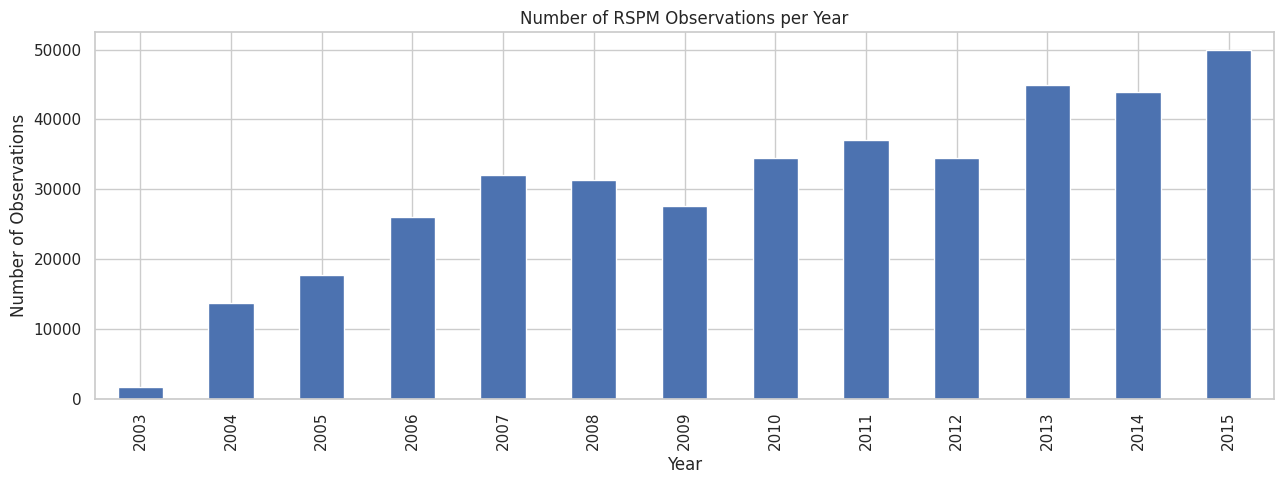

In [9]:
year_summary = (
    df_model.groupby(df_model["date"].dt.year)
    .agg(
        records=("rspm", "count"),
        average_rspm=("rspm", "mean"),
        median_rspm=("rspm", "median")
    )
)

display(year_summary)

plt.figure(figsize=(13, 5))
year_summary["records"].plot(kind="bar")
plt.title("Number of RSPM Observations per Year")
plt.xlabel("Year")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

---
# 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of RSPM
A histogram (with a density curve) and a boxplot of all RSPM readings.

**Insights**
- The distribution is **strongly right-skewed**: most readings sit between roughly 50 and 150 µg/m³, with a long tail of high-pollution days.
- The boxplot shows a dense band of outliers above about 280 µg/m³ and the isolated 6,307 reading far to the right.
- **Consequence for modelling:** a skewed target with large outliers can dominate squared-error training. This motivates (a) training the linear model and neural networks on `log(1 + RSPM)` and (b) reporting MAE alongside RMSE, because RMSE is heavily affected by a few large errors.

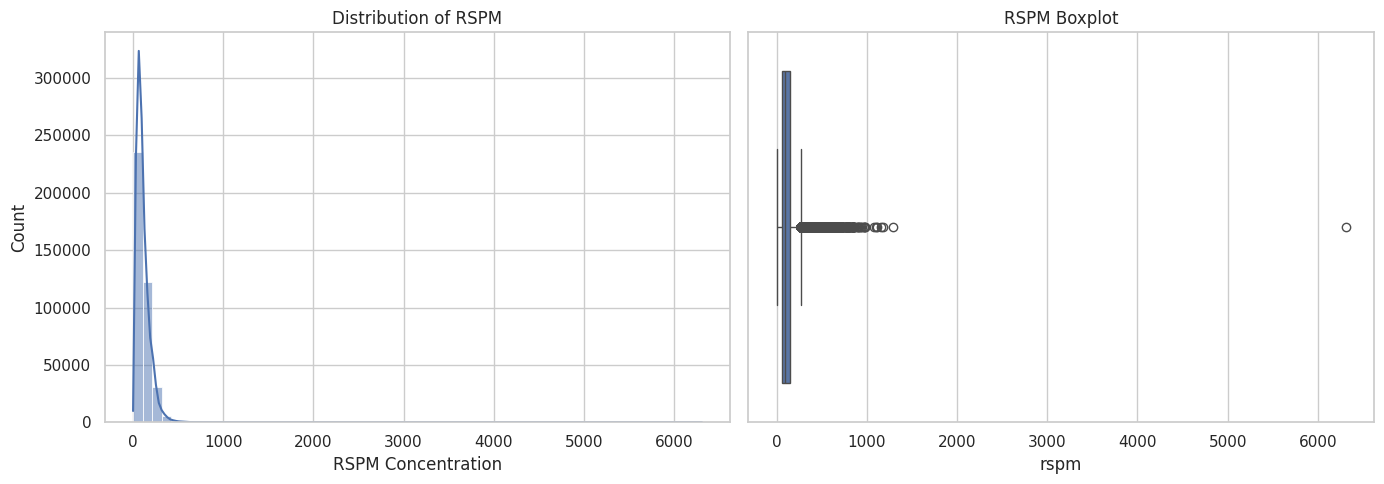

In [10]:
rspm_values = df_clean["rspm"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(rspm_values, bins=60, kde=True, ax=axes[0])
axes[0].set_title("Distribution of RSPM")
axes[0].set_xlabel("RSPM Concentration")

sns.boxplot(x=rspm_values, ax=axes[1])
axes[1].set_title("RSPM Boxplot")

plt.tight_layout()
plt.show()

### 4.2 Missing values by feature
A bar chart of the percentage of missing values in every column.

**Insights and feature-selection decisions**
- **`pm2_5` (97.9% missing)** — dropped; there is far too little data.
- **`spm` (54.5% missing)** — dropped. Besides the missing data, RSPM is a *subset* of SPM (RSPM is the respirable fraction of total suspended particles), so using SPM to predict RSPM would be close to target leakage.
- **`agency`, `stn_code`, `location_monitoring_station`** — dropped. They are identifiers with large gaps; the station's position is already captured by `state` and `location`.
- **`so2` (8.0%) and `no2` (3.7%)** — kept; the missing values are filled with the training median inside the preprocessing pipeline.
- **`type` (1.2%)** — kept; missing values become the category "Unknown".

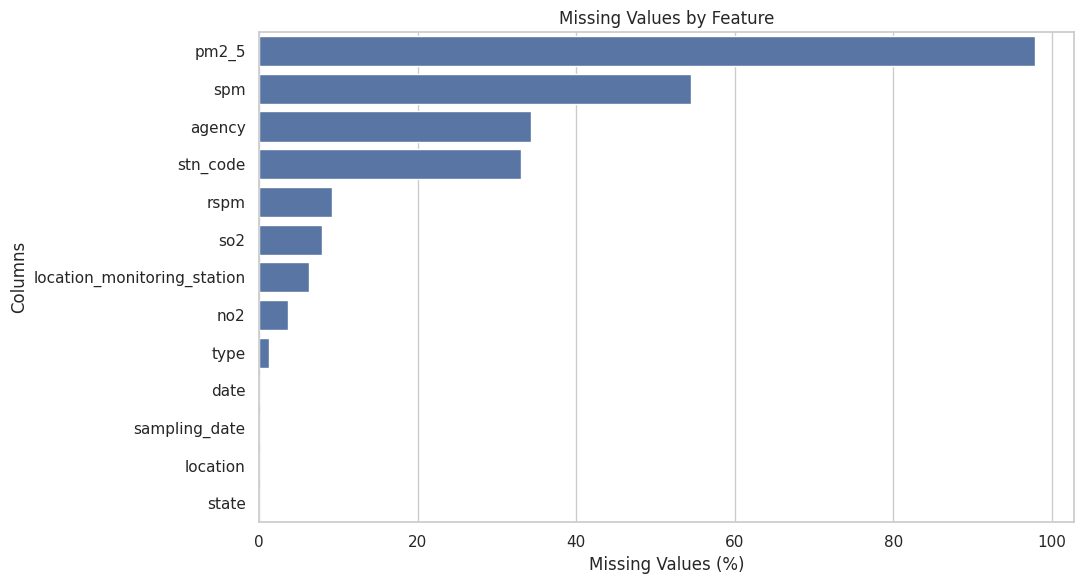

In [11]:
missing_percent = (df_clean.isnull().mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(11, 6))
sns.barplot(x=missing_percent.values, y=missing_percent.index)
plt.title("Missing Values by Feature")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.tight_layout()
plt.show()

### 4.3 Average RSPM by state
Mean RSPM for every state, sorted from most to least polluted.

**Insights**
- The most polluted states are **Delhi (197 µg/m³), Uttar Pradesh (177), Punjab (173) and Jharkhand (169)**, followed by Haryana, Uttarakhand and Rajasthan. Almost all of these lie in the **Indo-Gangetic Plain** of northern India, where dense industry, traffic, crop-residue burning and winter temperature inversions trap particulate matter.
- The cleanest are coastal, hilly or north-eastern regions: **Kerala (51), Puducherry (43), Mizoram (43) and Sikkim (32)**.
- Delhi's average is about **six times** Sikkim's, so the station's state is a strong predictor.
- **Data-quality finding:** *Uttarakhand* (149) and *Uttaranchal* (122) appear as separate states. Uttaranchal is the state's former name (renamed in 2007), so the two are merged in Section 5.1. Lakshadweep, Tripura and Andaman & Nicobar Islands have no RSPM readings at all.

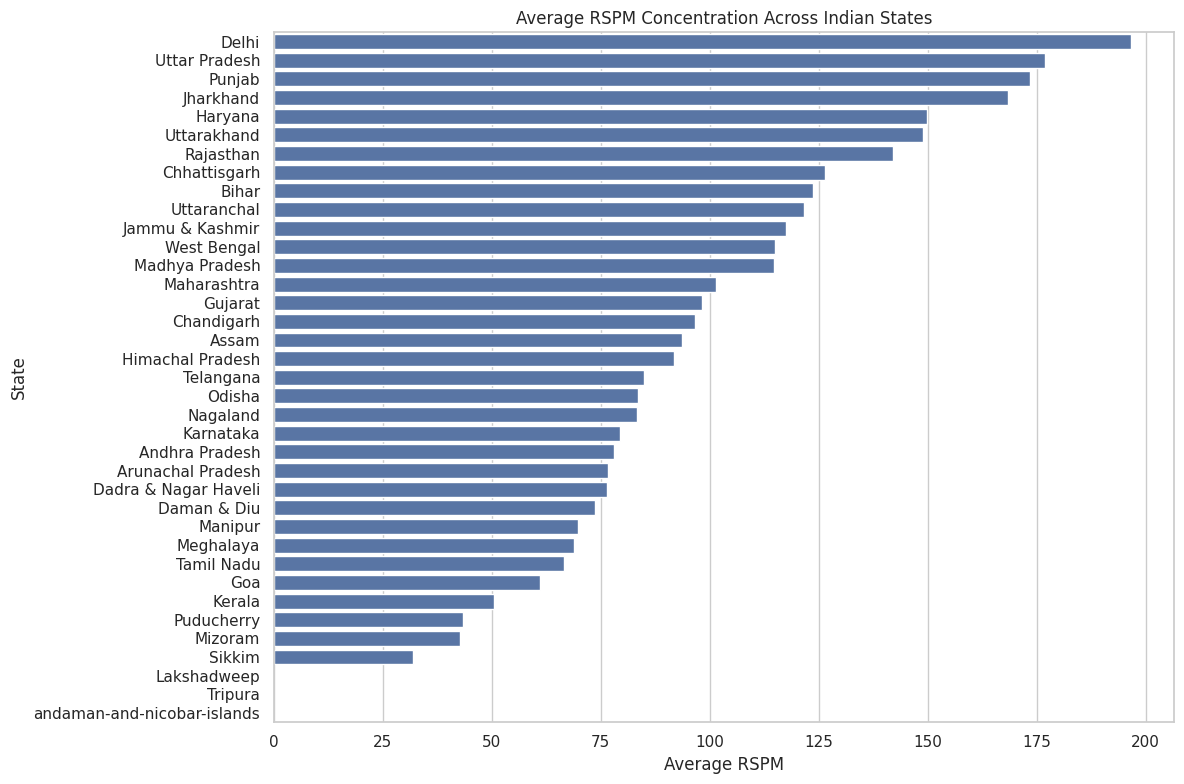

,Average RSPM
state,
Delhi,196.639771
Uttar Pradesh,176.952308
Punjab,173.493711
Jharkhand,168.517763
Haryana,149.860537
Uttarakhand,148.978906
Rajasthan,142.016832
Chhattisgarh,126.472399
Bihar,123.705176


In [12]:
state_pollution = (
    df_clean.groupby("state")["rspm"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))
sns.barplot(x=state_pollution.values, y=state_pollution.index)
plt.title("Average RSPM Concentration Across Indian States")
plt.xlabel("Average RSPM")
plt.ylabel("State")
plt.tight_layout()
plt.show()

display(state_pollution.to_frame("Average RSPM"))

### 4.4 Top 15 most polluted locations
Mean RSPM per city, restricted to cities with at least 30 readings so that a handful of measurements cannot produce a misleading average.

**Insights**
- The most polluted locations are **Ghaziabad (251), West Singhbhum (246), Bareilly (233), Allahabad (231) and Ludhiana (219)**.
- Nine of the 15 are in **Uttar Pradesh or Punjab** (e.g. Ghaziabad, Bareilly, Allahabad, Kanpur, Firozabad, Ludhiana, Khanna, Gobindgarh, Amritsar), confirming the state-level pattern.
- Industrial and mining towns (Jharia, West Singhbhum, Gobindgarh) feature strongly, which suggests the station's **area type** matters.
- Delhi, the most polluted *state*, ranks only 12th at city level — individual industrial cities are worse than the capital's average.

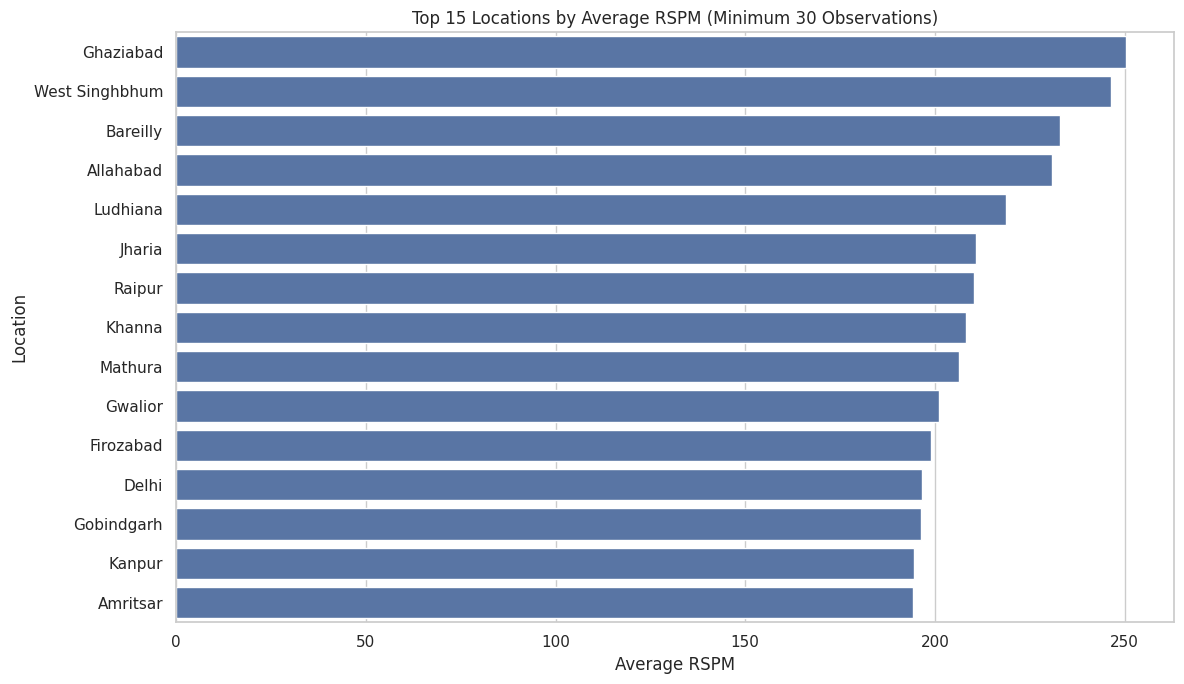

,average_rspm,observation_count
location,,
Ghaziabad,250.513254,1924
West Singhbhum,246.417219,151
Bareilly,233.038058,741
Allahabad,230.810709,1717
Ludhiana,218.633713,5761
Jharia,210.844414,802
Raipur,210.202634,1367
Khanna,208.194939,2134
Mathura,206.256410,78


In [13]:
location_pollution = (
    df_clean.dropna(subset=["rspm", "location"])
    .groupby("location")
    .agg(
        average_rspm=("rspm", "mean"),
        observation_count=("rspm", "count")
    )
    .query("observation_count >= 30")
    .sort_values("average_rspm", ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))
sns.barplot(data=location_pollution.reset_index(), x="average_rspm", y="location")
plt.title("Top 15 Locations by Average RSPM (Minimum 30 Observations)")
plt.xlabel("Average RSPM")
plt.ylabel("Location")
plt.tight_layout()
plt.show()

display(location_pollution)

### 4.5 Yearly RSPM trend
Average RSPM per year across all stations.

**Insights**
- 2003 shows a low average (89), but it is based on only 1,701 readings, so it is not representative.
- From 2004 to 2011 the national average stays between about **105 and 121 µg/m³**, peaking in **2004 (121)** and again in **2011 (116)**.
- From 2011 there is a steady **decline to 101 in 2015**.
- **Consequence for modelling:** the validation (2013–14) and test (2015) years are cleaner on average than the training years. A model trained on 2003–2012 may slightly *over-predict* later years. The `year` feature is included so the models can capture this trend, and the chronological split tests whether they generalise to future years.

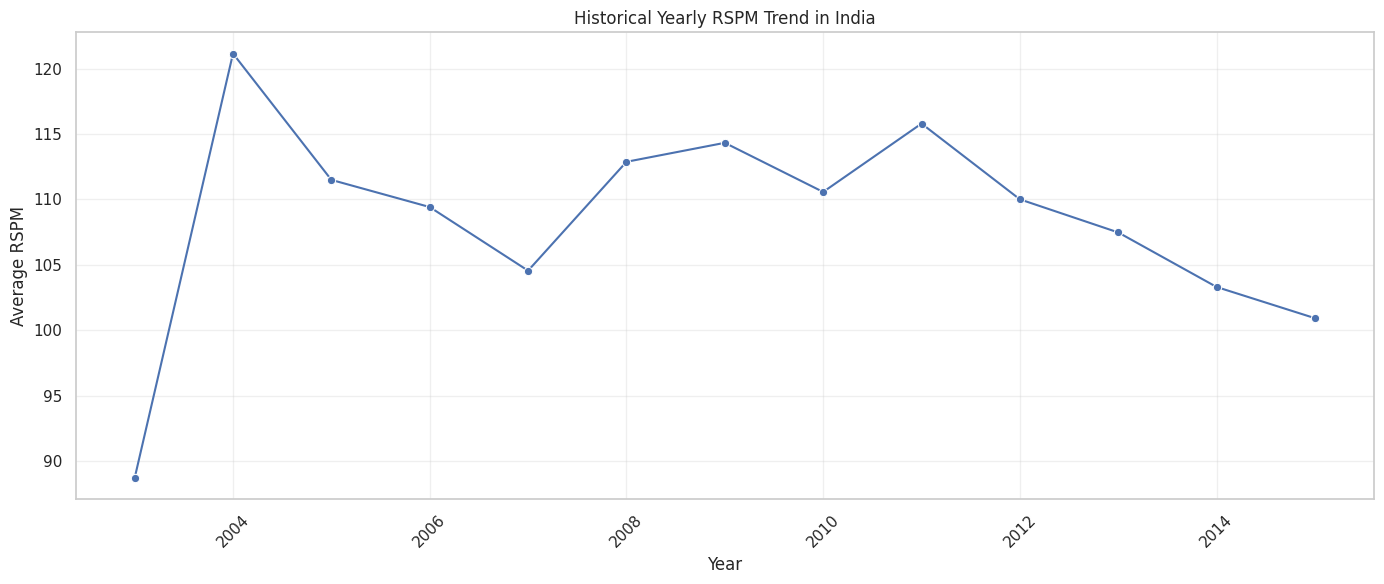

,year,average_rspm,observation_count
0,2003.0,88.706643,1701
1,2004.0,121.152107,13724
2,2005.0,111.497940,17715
3,2006.0,109.421053,26049
4,2007.0,104.559196,32080
5,2008.0,112.879093,31363
6,2009.0,114.330681,27649
7,2010.0,110.575186,34437
8,2011.0,115.800038,37188
9,2012.0,110.010378,34687


In [14]:
df_clean["year"] = df_clean["date"].dt.year

yearly_pollution = (
    df_clean.dropna(subset=["rspm", "year"])
    .groupby("year")
    .agg(
        average_rspm=("rspm", "mean"),
        observation_count=("rspm", "count")
    )
    .reset_index()
)

plt.figure(figsize=(14, 6))
sns.lineplot(data=yearly_pollution, x="year", y="average_rspm", marker="o")
plt.title("Historical Yearly RSPM Trend in India")
plt.xlabel("Year")
plt.ylabel("Average RSPM")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(yearly_pollution.tail(15))

### 4.6 Monthly (seasonal) pattern
Average RSPM for each calendar month.

**Insights**
- There is a clear **seasonal cycle**. Pollution is highest in **December (126) and January (122)**, stays high through February to May, and is lowest in the **monsoon months — August (89) and July (92)**.
- Winter readings are about **40% higher** than monsoon readings. Monsoon rain washes particles out of the air, while in winter cold, still air and temperature inversions trap pollutants near the ground, and crop-residue and domestic burning add more.
- Levels rise again quickly from October (109) to November (119), consistent with the post-harvest burning season in northern India.
- **Consequence for modelling:** month is an important feature. Because December and January are neighbours in time, the month is encoded with sine and cosine (Section 5.1) so the models see the year as a circle rather than treating December (12) and January (1) as far apart.

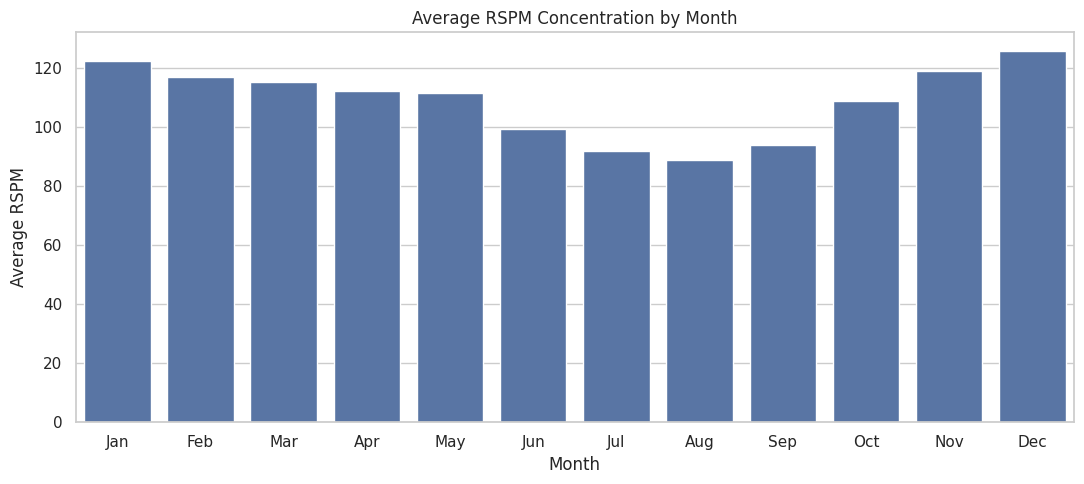

,Average RSPM
month,
1.0,122.435227
2.0,117.076940
3.0,115.227345
4.0,112.104296
5.0,111.689892
6.0,99.336301
7.0,91.857000
8.0,88.835387
9.0,93.916993


In [15]:
df_clean["month"] = df_clean["date"].dt.month

monthly_pollution = (
    df_clean.dropna(subset=["rspm", "month"])
    .groupby("month")["rspm"]
    .mean()
)

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(11, 5))
sns.barplot(x=month_names, y=monthly_pollution.reindex(range(1, 13)).values)
plt.title("Average RSPM Concentration by Month")
plt.xlabel("Month")
plt.ylabel("Average RSPM")
plt.tight_layout()
plt.show()

display(monthly_pollution.to_frame("Average RSPM"))

### 4.7 Correlation between pollutants
A heatmap of the Pearson correlation between RSPM, SO₂, NO₂ and SPM.

**Insights**
- **RSPM–SPM: 0.80**, a strong relationship, as expected, because RSPM is part of SPM. SPM is still excluded (see 4.2): it is missing in over half of the records and using it would come close to target leakage.
- **RSPM–NO₂: 0.37**, a moderate positive relationship. NO₂ comes mainly from vehicles and combustion, the same sources as fine particles, which makes NO₂ the most useful gas predictor.
- **RSPM–SO₂: 0.17**, a weak relationship. SO₂ comes mainly from specific industrial and power-plant sources.
- **SO₂–NO₂: 0.34**, which is low enough that both gases add separate information.
- No single gas explains RSPM well on its own, so the models must combine the gases with **location and seasonal** information.

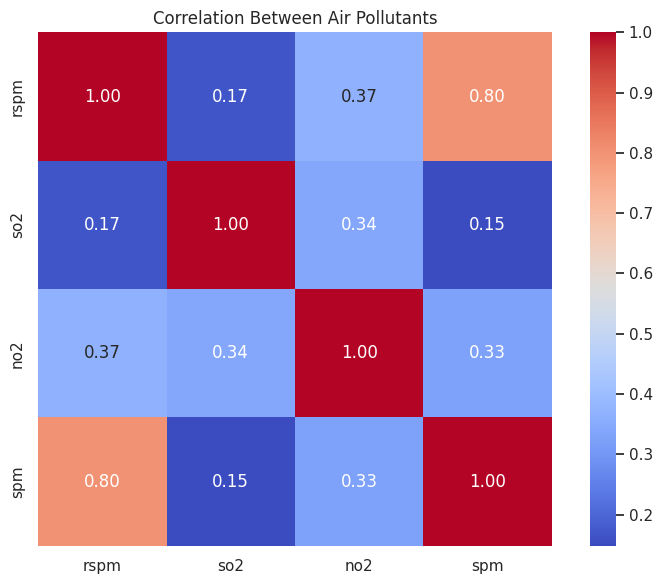

,rspm,so2,no2,spm
rspm,1.000000,0.165325,0.369923,0.801752
so2,0.165325,1.000000,0.340555,0.148325
no2,0.369923,0.340555,1.000000,0.326170
spm,0.801752,0.148325,0.326170,1.000000


In [16]:
pollutant_columns = ["rspm", "so2", "no2", "spm"]

correlation = df_clean[pollutant_columns].apply(pd.to_numeric, errors="coerce").corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Between Air Pollutants")
plt.tight_layout()
plt.show()

display(correlation)

---
# 5. Model / Pipeline Design and Building

### 5.1 Feature engineering and category harmonisation
This cell prepares the final feature set.

1. **Text clean-up** — `state`, `location` and `type` are trimmed and put in title case; missing values become "Unknown".
2. **Category harmonisation** (data-quality fixes found during EDA and in the first SHAP analysis):
   - the station `type` column records the same three kinds of area under several spellings (e.g. *Industrial Area*, *Industrial Areas*, *Residential, Rural and other Areas*, *Residential and others*, *RIRUO*, *Sensitive Area*, *Sensitive Areas*). These are mapped to **Industrial, Residential and Sensitive**;
   - the former state name **Uttaranchal** is merged into **Uttarakhand**;
   - the former city name **Calcutta** is merged into **Kolkata**.
3. **Time features** — `year` and `month` are extracted from the date. Month is converted to `month_sin` and `month_cos` (cyclical encoding), so December and January sit next to each other.
4. **Feature set** — SO₂, NO₂, state, location, area type, year and the two month features. SPM is deliberately excluded (see 4.2 and 4.7).

In [17]:
categorical_columns = ["state", "location", "type"]

for col in categorical_columns:
    df_model[col] = (
        df_model[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.title()
    )

print("Area-type labels BEFORE harmonisation:")
display(df_model["type"].value_counts())

def harmonise_area_type(value):
    v = str(value).lower()
    if "industrial" in v:
        return "Industrial"
    if "sensitive" in v:
        return "Sensitive"
    if "residential" in v or "riruo" in v:
        return "Residential"
    return "Unknown"

df_model["type"] = df_model["type"].apply(harmonise_area_type)
df_model["state"] = df_model["state"].replace({"Uttaranchal": "Uttarakhand"})
df_model["location"] = df_model["location"].replace({"Calcutta": "Kolkata"})

print("\nArea-type labels AFTER harmonisation:")
display(df_model["type"].value_counts())

# Numerical pollutant features
df_model["so2"] = pd.to_numeric(df_model["so2"], errors="coerce")
df_model["no2"] = pd.to_numeric(df_model["no2"], errors="coerce")

# Time features
df_model["year"] = df_model["date"].dt.year
df_model["month"] = df_model["date"].dt.month
df_model["month_sin"] = np.sin(2 * np.pi * df_model["month"] / 12)
df_model["month_cos"] = np.cos(2 * np.pi * df_model["month"] / 12)

features = ["so2", "no2", "state", "location", "type", "year", "month_sin", "month_cos"]
target = "rspm"

print("\nFeatures selected:", features)
print("Target:", target)

print("\nFeature dataset:")
display(df_model[features + [target]].head())

print("\nMissing feature values:")
display(df_model[features].isnull().sum())

Area-type labels BEFORE harmonisation:


type
Residential, Rural And Other Areas    165552
Industrial Area                        84461
Residential And Others                 81852
Industrial Areas                       47630
Sensitive Area                          8656
Sensitive Areas                         5374
Riruo                                   1304
Unknown                                  200
Name: count, dtype: int64


Area-type labels AFTER harmonisation:


type
Residential    248708
Industrial     132091
Sensitive       14030
Unknown           200
Name: count, dtype: int64


Features selected: ['so2', 'no2', 'state', 'location', 'type', 'year', 'month_sin', 'month_cos']
Target: rspm

Feature dataset:


,so2,no2,state,location,type,year,month_sin,month_cos,rspm
1036,12.9,55.8,Andhra Pradesh,Hyderabad,Industrial,2004,8.660254e-01,5.000000e-01,143.7
1037,10.4,48.9,Andhra Pradesh,Hyderabad,Industrial,2004,5.000000e-01,-8.660254e-01,124.7
1038,7.6,50.1,Andhra Pradesh,Hyderabad,Industrial,2004,-1.000000e+00,-1.836970e-16,88.0
1039,7.3,48.5,Andhra Pradesh,Hyderabad,Industrial,2004,-2.449294e-16,1.000000e+00,82.7
1040,6.8,110.3,Andhra Pradesh,Hyderabad,Industrial,2004,5.000000e-01,8.660254e-01,122.3



Missing feature values:


so2          28795
no2          11628
state            0
location         0
type             0
year             0
month_sin        0
month_cos        0
dtype: int64

### 5.2 Chronological train / validation / test split
The data is split **by time**, not at random, because the real use case is predicting pollution in years the model has not seen. A random split would let the model "see the future" and overstate its accuracy.

| Split | Years | Rows | Purpose |
|---|---|---|---|
| Training | 2003–2012 | 256,231 | fit the models |
| Validation | 2013–2014 | 88,808 | compare models and tune hyperparameters |
| Test | 2015 | 49,990 | final, untouched evaluation |

**Insight:** the target distribution shifts over time. Mean RSPM falls from 111.6 (train) to 105.5 (validation) to 100.9 (test), and the training set contains the extreme 6,307 reading while the maximum in validation is 981. This confirms that the test is a realistic "future year" scenario.

In [18]:
train_df = df_model[df_model["year"] <= 2012].copy()
val_df = df_model[df_model["year"].isin([2013, 2014])].copy()
test_df = df_model[df_model["year"] == 2015].copy()

X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]

print("TRAINING SET  :", X_train.shape, "| years", train_df["year"].min(), "-", train_df["year"].max())
print("VALIDATION SET:", X_val.shape, "| years", sorted(val_df["year"].unique()))
print("TEST SET      :", X_test.shape, "| years", sorted(test_df["year"].unique()))

print("\nTarget distribution by split:")
display(pd.DataFrame({
    "Train": y_train.describe(),
    "Validation": y_val.describe(),
    "Test": y_test.describe()
}))

TRAINING SET  : (256231, 8) | years 2003 - 2012
VALIDATION SET: (88808, 8) | years [np.int32(2013), np.int32(2014)]
TEST SET      : (49990, 8) | years [np.int32(2015)]

Target distribution by split:


,Train,Validation,Test
count,256231.000000,88808.000000,49990.000000
mean,111.601488,105.468814,100.927573
std,78.219667,70.419511,63.547603
min,0.000000,0.000000,2.000000
25%,56.300000,55.000000,57.000000
50%,92.000000,87.000000,85.000000
75%,146.000000,137.000000,130.000000
max,6307.033333,981.000000,892.000000


### 5.3 Preprocessing pipeline (traditional models and MLP)
A scikit-learn `ColumnTransformer` prepares the inputs in the same way for every traditional model and for the MLP:

- **Numeric features** (SO₂, NO₂, year, month_sin, month_cos): missing values filled with the **training median**, then standardised to mean 0 and standard deviation 1.
- **Categorical features** (state, location, area type): missing values filled with the most frequent category, then **one-hot encoded**. Categories with fewer than 20 training records are grouped together (`min_frequency=20`), and categories not seen in training are ignored (`handle_unknown="ignore"`), so a new station in a later year does not break the pipeline.

The pipeline is **fitted on the training data only** and then applied to the validation and test data. This prevents information from later years leaking into training.

**Result:** each record becomes a sparse vector of **261 features** (5 numeric plus 256 one-hot columns for states, locations and area types), with no missing values. Merging the duplicate area-type labels in Section 5.1 reduced the feature count from 266 in the first version of this notebook.

In [19]:
numeric_features = ["so2", "no2", "year", "month_sin", "month_cos"]
categorical_features = ["state", "location", "type"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=20))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=1.0
)

# Fit on training data only, then transform every split
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Training matrix shape  :", X_train_processed.shape)
print("Validation matrix shape:", X_val_processed.shape)
print("Test matrix shape      :", X_test_processed.shape)
print("Matrix type:", type(X_train_processed).__name__)

train_nan = np.isnan(X_train_processed.data).sum() if issparse(X_train_processed) else np.isnan(X_train_processed).sum()
print("Missing values in training matrix:", train_nan)

Training matrix shape  : (256231, 261)
Validation matrix shape: (88808, 261)
Test matrix shape      : (49990, 261)
Matrix type: csr_matrix
Missing values in training matrix: 0


---
# 6. Model Training — Traditional Machine Learning

### 6.1 Evaluation function and prediction safeguard
Every model is scored on the validation set with the same three metrics:

- **MAE** (Mean Absolute Error) — the average size of the error in µg/m³; easy to interpret.
- **RMSE** (Root Mean Squared Error) — penalises large errors more heavily.
- **R²** — the share of the variation in RSPM that the model explains (1 = perfect, 0 = no better than predicting the average).

**Prediction safeguard for log-scale models.** Ridge Regression and both neural networks are trained on `log(1 + RSPM)` and their predictions are converted back with `exp(x) − 1`. Because the exponential grows very fast, a single unusual input can turn a moderately high log prediction into an absurd value (the first version of this notebook produced RSPM predictions of about **10 million µg/m³**; see Section 6.3). The `to_rspm_scale` function therefore **caps log predictions at the 99.9th percentile of the training target** before converting them back. The cap is computed from training data only, so no information leaks from validation or test.

The training 99.9th percentile gives a cap of **6.354 on the log scale, i.e. a maximum prediction of 573.8 µg/m³** — above 99.9% of all training readings.

The results of every model are stored in `validation_results` and `val_predictions` for the comparison in Section 9.

In [20]:
def evaluate_model(name, actual, predicted):
    predicted = np.maximum(np.asarray(predicted), 0)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return {"Model": name, "MAE": round(mae, 3), "RMSE": round(rmse, 3), "R2": round(r2, 4)}

# Upper limit for log-scale predictions, learned from the training target only
LOG_CAP = np.log1p(y_train.quantile(0.999))

def to_rspm_scale(pred_log):
    # Convert log(1 + RSPM) predictions back to RSPM, capped at the training 99.9th percentile
    return np.expm1(np.clip(pred_log, 0, LOG_CAP))

validation_results = []
val_predictions = {}

def record_result(name, predictions):
    val_predictions[name] = np.asarray(predictions)
    result = evaluate_model(name, y_val, predictions)
    validation_results.append(result)
    return pd.DataFrame([result])

print(f"Log-prediction cap: {LOG_CAP:.3f}  ->  maximum predicted RSPM = {np.expm1(LOG_CAP):.1f} µg/m³")

Log-prediction cap: 6.354  ->  maximum predicted RSPM = 573.8 µg/m³


### 6.2 Baseline models: median predictor and Ridge Regression
- **Median baseline** — predicts the training median for every record. Any useful model must beat it.
- **Ridge Regression** — a linear model with L2 regularisation (`alpha = 10`), trained on `log(1 + RSPM)` to reduce the influence of the skewed target. Its predictions are converted back with the capped `to_rspm_scale` function.

**Results**
| Model | MAE | RMSE | R² |
|---|---|---|---|
| Median baseline | 50.55 | 71.70 | −0.037 |
| Ridge Regression (α = 10) | 37.45 | 57.21 | 0.340 |

- The median baseline has a slightly **negative R²**. Predicting one fixed value is worse than predicting the validation mean, and it is wrong by about 51 µg/m³ on average. This is the floor every real model must beat.
- Ridge Regression cuts the MAE by **26%** (from 50.5 to 37.4) and explains **34%** of the variation in RSPM. Even a simple linear combination of gases, place and season carries real predictive signal.
- With the prediction cap in place, Ridge now gives sensible results. Without it, the same model scored R² ≈ −239,000 in the first version of this notebook (see 6.3).

In [21]:
y_train_log = np.log1p(y_train)

# Baseline 1: training median for every observation
dummy_model = DummyRegressor(strategy="median")
dummy_model.fit(X_train_processed, y_train)
dummy_predictions = dummy_model.predict(X_val_processed)

# Baseline 2: Ridge Regression on log(1 + RSPM)
ridge_model = Ridge(alpha=10.0, solver="lsqr")
ridge_model.fit(X_train_processed, y_train_log)

ridge_predictions_log = ridge_model.predict(X_val_processed)   # raw log-scale output (kept for diagnosis)
ridge_predictions = to_rspm_scale(ridge_predictions_log)

display(pd.concat([
    record_result("Median Baseline", dummy_predictions),
    record_result("Ridge Regression (alpha=10)", ridge_predictions)
], ignore_index=True))

,Model,MAE,RMSE,R2
0,Median Baseline,50.545,71.696,-0.0366
1,Ridge Regression (alpha=10),37.448,57.211,0.3400


### 6.3 Diagnosing Ridge Regression's extreme predictions
This cell shows **why the prediction cap is needed**. It compares Ridge's raw log-scale predictions with what they would become *without* the cap, and lists the records with the largest uncapped predictions together with their input values.

**What the diagnosis shows**
- Most of Ridge's log predictions are reasonable (mean 4.52, i.e. about 90 µg/m³), but the highest reaches **16.15**, which converts to **10.3 million µg/m³**.
- Only **113 of 88,808** validation predictions (0.13%) exceed the cap, so the cap removes the explosions without changing normal predictions.
- Every one of those extreme predictions belongs to a record with an **unusually high NO₂ reading** (for example 876 µg/m³ in Jaipur and 696 µg/m³ in Nalagarh, against a typical NO₂ of 20–40). Many are Kolkata records with NO₂ above 250.
- **Cause:** Ridge is linear in log space, so NO₂ adds to the log prediction at a constant rate and grows without limit. Converting back with the exponential turns that unbounded linear growth into exponential growth. Without the cap, these few records produced R² ≈ −239,000.
- **Remedy:** capping the log prediction at the training 99.9th percentile keeps every prediction physically plausible while leaving normal predictions unchanged.

In [22]:
uncapped = np.expm1(ridge_predictions_log)

print("Ridge log-scale predictions : min {:.2f} | mean {:.2f} | max {:.2f}".format(
    ridge_predictions_log.min(), ridge_predictions_log.mean(), ridge_predictions_log.max()))
print("Without cap (µg/m³)         : max {:,.0f}".format(uncapped.max()))
print("With cap (µg/m³)            : max {:,.1f}".format(ridge_predictions.max()))
print("Predictions affected by cap :", int((ridge_predictions_log > LOG_CAP).sum()), "of", len(ridge_predictions_log))

ridge_diagnostics = X_val[["so2", "no2", "state", "location", "type"]].copy()
ridge_diagnostics["actual_rspm"] = y_val.values
ridge_diagnostics["uncapped_prediction"] = uncapped
ridge_diagnostics["capped_prediction"] = ridge_predictions

print("\nRecords with the largest uncapped Ridge predictions:")
display(ridge_diagnostics.nlargest(12, "uncapped_prediction"))

Ridge log-scale predictions : min 2.95 | mean 4.52 | max 16.15
Without cap (µg/m³)         : max 10,277,460
With cap (µg/m³)            : max 573.8
Predictions affected by cap : 113 of 88808

Records with the largest uncapped Ridge predictions:


,so2,no2,state,location,type,actual_rspm,uncapped_prediction,capped_prediction
340312,8.0,876.0,Rajasthan,Jaipur,Residential,231.0,1.027746e+07,573.8459
124236,2.0,696.0,Himachal Pradesh,Nalagarh,Residential,92.0,7.284221e+05,573.8459
433055,55.0,444.0,West Bengal,Kolkata,Industrial,284.0,2.491209e+04,573.8459
399101,18.0,403.0,Uttar Pradesh,Anpara,Industrial,146.0,1.993616e+04,573.8459
433059,100.0,366.0,West Bengal,Kolkata,Industrial,334.0,1.012920e+04,573.8459
433157,24.0,377.0,West Bengal,Kolkata,Residential,155.0,8.353056e+03,573.8459
433056,44.0,348.0,West Bengal,Kolkata,Industrial,278.0,6.458970e+03,573.8459
433147,46.0,341.0,West Bengal,Kolkata,Residential,222.0,4.889327e+03,573.8459
433058,81.0,314.0,West Bengal,Kolkata,Industrial,376.0,4.808241e+03,573.8459
433090,2.0,349.0,West Bengal,Kolkata,Residential,80.0,4.698944e+03,573.8459


### 6.4 Random Forest
A Random Forest averages the predictions of 100 decision trees, each trained on a random sample of records and features. Trees capture non-linear effects and interactions (for example *industrial area in Uttar Pradesh in winter*) that a linear model cannot.

Settings: `max_depth=20` and `min_samples_leaf=5` limit how far each tree can grow, to prevent overfitting; `max_features=0.7` lets each split consider 70% of the features, so the trees differ from one another. The forest predicts RSPM directly (no log transform), because trees are not affected by the skewed target the way a linear model is.

**Results:** MAE **35.14**, RMSE **52.20**, R² **0.451**.

The Random Forest explains **45%** of the variation, compared with 34% for Ridge, and lowers the MAE by a further 2.3 µg/m³. The gain comes from the trees' ability to model **non-linear effects and interactions**. For example, the effect of NO₂ can differ between an industrial area in Uttar Pradesh and a residential area in Kerala, which a single linear equation cannot represent.

In [23]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    max_features=0.7,
    n_jobs=-1,
    random_state=SEED
)

rf_model.fit(X_train_processed, y_train)
rf_predictions = rf_model.predict(X_val_processed)

display(record_result("Random Forest", rf_predictions))

,Model,MAE,RMSE,R2
0,Random Forest,35.142,52.198,0.4506


### 6.5 XGBoost (gradient-boosted trees)
XGBoost builds trees **one after another**, each new tree correcting the errors of the trees before it. It is usually the strongest traditional method on tabular data like this.

Initial settings: 300 trees, maximum depth 8, learning rate 0.05, and 80% row and column sampling per tree (`subsample`, `colsample_bytree`), which adds randomness and reduces overfitting. `tree_method="hist"` makes training fast on large datasets. These settings are tuned in Section 8.2.

**Results:** MAE **34.06**, RMSE **50.47**, R² **0.486**.

Even before tuning, XGBoost is the strongest model so far: it improves on the Random Forest in every metric (R² 0.486 vs 0.451). Boosting fits each new tree to the *remaining* errors of the trees before it, so it keeps refining the difficult cases that an average of independent trees (Random Forest) smooths over.

In [24]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=-1,
    random_state=SEED
)

xgb_model.fit(X_train_processed, y_train)
xgb_predictions = xgb_model.predict(X_val_processed)

display(record_result("XGBoost (default)", xgb_predictions))

,Model,MAE,RMSE,R2
0,XGBoost (default),34.06,50.465,0.4864


---
# 7. Model Training — Deep Learning
Two neural networks are trained:

1. **Model A — Feed-forward MLP** on the same one-hot inputs as the traditional models. This is the standard deep-learning baseline for tabular data.
2. **Model B — Entity-embedding neural network**, a stronger architecture designed for tabular data with many categories. Instead of 300-plus one-hot columns, each state, location and area type is mapped to a small, **learned vector (embedding)**. Locations with similar pollution behaviour end up with similar vectors, so the network can share what it learns between related stations. This technique comes from the Rossmann sales-forecasting competition (Guo & Berkhahn, 2016, *Entity Embeddings of Categorical Variables*).

Both networks are trained on `log(1 + RSPM)` with the **Huber loss**, which behaves like squared error for small errors and like absolute error for large ones, so the rare extreme readings do not dominate training.

### 7.1 Model A — prepare inputs for the MLP
Keras needs dense (not sparse) arrays, so the one-hot matrices are converted to dense `float32` arrays. The target is log-transformed. The training matrix is about 260 MB, which fits comfortably in Kaggle's memory.

In [25]:
def to_dense(matrix):
    return (matrix.toarray() if issparse(matrix) else np.asarray(matrix)).astype("float32")

X_train_nn = to_dense(X_train_processed)
X_val_nn = to_dense(X_val_processed)
X_test_nn = to_dense(X_test_processed)

y_train_nn = np.log1p(y_train.to_numpy()).astype("float32")
y_val_nn = np.log1p(y_val.to_numpy()).astype("float32")

print("Training features  :", X_train_nn.shape)
print("Validation features:", X_val_nn.shape)
print("Training data memory:", round(X_train_nn.nbytes / 1024**2, 1), "MB")

Training features  : (256231, 261)
Validation features: (88808, 261)
Training data memory: 255.1 MB


### 7.2 Model A — build the MLP
Architecture: input → Dense(128, ReLU) → Dropout(0.2) → Dense(64, ReLU) → Dropout(0.2) → Dense(32, ReLU) → Dense(1, linear).

- **Dense layers** learn combinations of the input features.
- **Dropout** randomly switches off 20% of neurons during training, which reduces overfitting.
- The **linear output** produces the predicted `log(1 + RSPM)`.
- Optimiser: **Adam** (learning rate 0.001). Loss: **Huber**.

In [26]:
tf.keras.utils.set_random_seed(SEED)

mlp_model = keras.Sequential([
    layers.Input(shape=(X_train_nn.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="linear")
], name="mlp_one_hot")

mlp_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.Huber(),
    metrics=["mae"]
)

mlp_model.summary()

Model: "mlp_one_hot"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        33,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,905 (171.50 KB)

 Trainable params: 43,905 (171.50 KB)

 Non-trainable params: 0 (0.00 B)

### 7.3 Model A — train the MLP
The network is trained for up to 50 epochs in batches of 1,024 records. Two callbacks control training:

- **EarlyStopping** stops when the validation loss has not improved for 5 epochs and **restores the best weights**, so the final model is the best one seen rather than the last one.
- **ReduceLROnPlateau** halves the learning rate when the validation loss stops improving, letting the network settle into a better minimum.

The learning curve plotted afterwards shows the training and validation loss per epoch. A validation curve that rises while the training curve keeps falling indicates overfitting.

Epoch 1/50
251/251 - 8s - 33ms/step - loss: 0.4410 - mae: 0.7814 - val_loss: 0.1195 - val_mae: 0.3787 - learning_rate: 0.0010
Epoch 2/50
251/251 - 1s - 4ms/step - loss: 0.1714 - mae: 0.4638 - val_loss: 0.1369 - val_mae: 0.4179 - learning_rate: 0.0010
Epoch 3/50
251/251 - 1s - 4ms/step - loss: 0.1431 - mae: 0.4173 - val_loss: 0.2152 - val_mae: 0.5555 - learning_rate: 0.0010
Epoch 4/50
251/251 - 1s - 4ms/step - loss: 0.1252 - mae: 0.3850 - val_loss: 0.2195 - val_mae: 0.5634 - learning_rate: 5.0000e-04
Epoch 5/50
251/251 - 1s - 4ms/step - loss: 0.1173 - mae: 0.3690 - val_loss: 0.2290 - val_mae: 0.5794 - learning_rate: 5.0000e-04
Epoch 6/50
251/251 - 1s - 4ms/step - loss: 0.1118 - mae: 0.3584 - val_loss: 0.2363 - val_mae: 0.5913 - learning_rate: 2.5000e-04


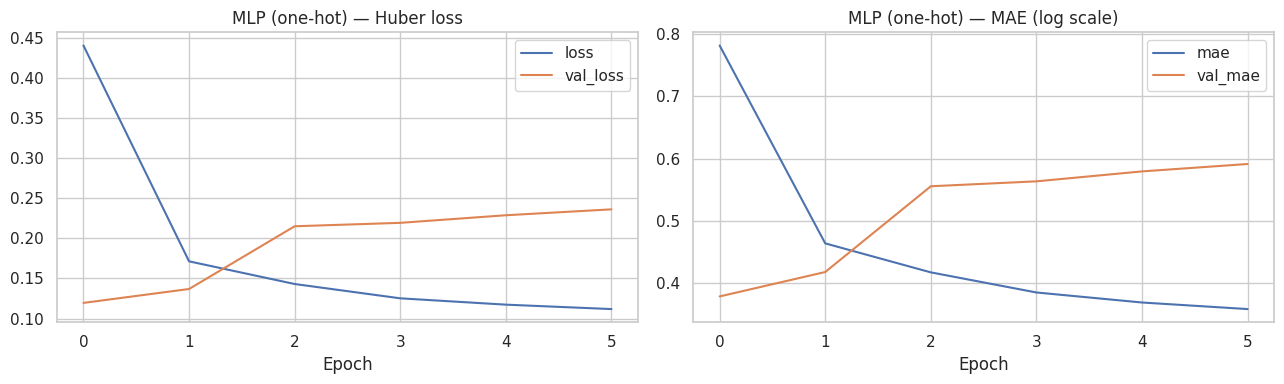

In [27]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    hist[["loss", "val_loss"]].plot(ax=axes[0])
    axes[0].set_title(f"{title} — Huber loss")
    axes[0].set_xlabel("Epoch")
    hist[["mae", "val_mae"]].plot(ax=axes[1])
    axes[1].set_title(f"{title} — MAE (log scale)")
    axes[1].set_xlabel("Epoch")
    plt.tight_layout()
    plt.show()

mlp_history = mlp_model.fit(
    X_train_nn, y_train_nn,
    validation_data=(X_val_nn, y_val_nn),
    epochs=50,
    batch_size=1024,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
    ],
    verbose=2
)

plot_history(mlp_history, "MLP (one-hot)")

### 7.4 Model A — evaluate the MLP
Predictions are converted back from the log scale with the capped `to_rspm_scale` function and scored with the same metrics as the traditional models. The cell also reports how many raw predictions would have exceeded the cap. In the first version of this notebook, the uncapped MLP produced predictions of up to 2.3 million µg/m³ (R² ≈ −11,900) — the same problem as Ridge, again caused by records with very high NO₂. This time **101 raw predictions** exceeded the cap and were limited to 573.8 µg/m³.

**Results:** MAE **37.07**, RMSE **56.71**, R² **0.351**.

**Learning curve insight.** The MLP reached its **best validation loss after the first epoch**. From then on the training loss kept falling while the validation loss *rose* (from 0.12 to 0.24): a clear sign of **overfitting**. EarlyStopping restored the epoch-1 weights. With 261 mostly one-hot inputs, the network quickly memorises station-specific patterns from 2003–2012 that do not carry over to 2013–2014. The MLP ends up only slightly better than Ridge (R² 0.351 vs 0.340) and well behind the tree models. This motivates the embedding architecture in Model B, which represents locations far more compactly.

In [28]:
mlp_predictions_log = mlp_model.predict(X_val_nn, batch_size=4096, verbose=0).ravel()
mlp_predictions = to_rspm_scale(mlp_predictions_log)

print("Raw log predictions above the cap:", int((mlp_predictions_log > LOG_CAP).sum()))

display(record_result("Neural Network A — MLP (one-hot)", mlp_predictions))

Raw log predictions above the cap: 101


,Model,MAE,RMSE,R2
0,Neural Network A — MLP (one-hot),37.068,56.712,0.3514


### 7.5 Model B — prepare inputs for the entity-embedding network
The embedding network receives two kinds of input.

**Categorical inputs.** Each state, location and area type seen in training gets an integer ID (1, 2, 3 …). ID 0 is reserved for categories that appear only in validation or test, such as a newly opened station.

**Numeric inputs** — seven features, all standardised using training statistics:
- `so2_log`, `no2_log`: the gas readings, capped at their training 99.9th percentile and log-transformed. This tames the very high NO₂ values that broke Ridge and the MLP.
- `so2_missing`, `no2_missing`: 1 if the reading was missing (and filled with the training median), otherwise 0. This lets the network learn whether a missing reading itself carries information.
- `year`, `month_sin`, `month_cos`.

**Teaching the network an "unknown station".** ID 0 would otherwise never appear during training, so its embedding would stay at its random starting values, and every new station would get a meaningless representation. To prevent this, **5% of training locations and 2% of training states are randomly relabelled as ID 0** (a technique sometimes called category dropout). The network therefore learns what an "average" station or state looks like, and uses that knowledge for stations it has never seen. Validation and test data are not changed.

**Target:** `log(1 + RSPM)`, standardised to mean 0 and standard deviation 1, which helps the network train faster and more stably.

**Output insight.** Training contains **31 states, 225 locations and 4 area types**. In the validation years, **1,855 records (2.1%)** come from a state and **5,724 records (6.4%)** from a location that never appears in training — new monitoring stations opened after 2012, and Telangana, which was created in 2014. These records receive ID 0, which now has a trained "average station" embedding. This shows the real-world challenge of predicting for stations with no history.

In [29]:
cat_cols = ["state", "location", "type"]

# Integer IDs learned from the training data (0 = unseen category)
cat_maps = {
    col: {value: i + 1 for i, value in enumerate(sorted(train_df[col].unique()))}
    for col in cat_cols
}

nn_medians = {c: float(train_df[c].median()) for c in ["so2", "no2"]}
nn_caps = {c: float(train_df[c].quantile(0.999)) for c in ["so2", "no2"]}

def make_numeric_block(frame):
    out = pd.DataFrame(index=frame.index)
    for c in ["so2", "no2"]:
        out[f"{c}_missing"] = frame[c].isna().astype("float32")
        out[f"{c}_log"] = np.log1p(frame[c].fillna(nn_medians[c]).clip(0, nn_caps[c]))
    out["year"] = frame["year"].astype("float32")
    out["month_sin"] = frame["month_sin"]
    out["month_cos"] = frame["month_cos"]
    return out

numeric_train_block = make_numeric_block(train_df)
num_mean = numeric_train_block.mean()
num_std = numeric_train_block.std().replace(0, 1)

def make_embedding_inputs(frame):
    numeric = ((make_numeric_block(frame) - num_mean) / num_std).to_numpy("float32")
    categorical = [
        frame[col].map(cat_maps[col]).fillna(0).astype("int32").to_numpy().reshape(-1, 1)
        for col in cat_cols
    ]
    return [numeric] + categorical

X_train_emb = make_embedding_inputs(train_df)
X_val_emb = make_embedding_inputs(val_df)
X_test_emb = make_embedding_inputs(test_df)

# Category dropout: relabel a small share of training IDs as 0 ("unknown"),
# so the unknown embedding is trained and new stations get a sensible representation
UNKNOWN_RATE = {"state": 0.02, "location": 0.05, "type": 0.0}
mask_rng = np.random.default_rng(SEED)
for col in cat_cols:
    ids = X_train_emb[1 + cat_cols.index(col)]
    mask = mask_rng.random(len(ids)) < UNKNOWN_RATE[col]
    ids[mask] = 0
    print(f"{col:9s}: {mask.sum():6d} training records relabelled as unknown ({UNKNOWN_RATE[col]:.0%})")
print()

# Standardised log target
y_log_mean = float(np.log1p(y_train).mean())
y_log_std = float(np.log1p(y_train).std())
y_train_emb = ((np.log1p(y_train) - y_log_mean) / y_log_std).to_numpy("float32")
y_val_emb = ((np.log1p(y_val) - y_log_mean) / y_log_std).to_numpy("float32")

def predict_embedding_nn(model, inputs):
    pred_std = model.predict(inputs, batch_size=4096, verbose=0).ravel()
    return to_rspm_scale(pred_std * y_log_std + y_log_mean)

print("Numeric input features:", list(numeric_train_block.columns))
for col in cat_cols:
    unseen_val = (X_val_emb[1 + cat_cols.index(col)] == 0).sum()
    print(f"{col:9s}: {len(cat_maps[col]):3d} training categories | unseen in validation: {unseen_val}")

state    :   5080 training records relabelled as unknown (2%)
location :  12816 training records relabelled as unknown (5%)
type     :      0 training records relabelled as unknown (0%)

Numeric input features: ['so2_missing', 'so2_log', 'no2_missing', 'no2_log', 'year', 'month_sin', 'month_cos']
state    :  31 training categories | unseen in validation: 1855
location : 225 training categories | unseen in validation: 5724
type     :   4 training categories | unseen in validation: 0


### 7.6 Model B — build the entity-embedding network
`build_embedding_nn` creates the network from a set of hyperparameters, so the same function can be reused for tuning in Section 8.3.

**Architecture**
1. Each categorical input passes through its own **Embedding layer** (state → 8 numbers, location → 16, area type → 3 in the default configuration).
2. The embeddings are flattened and **concatenated** with the seven numeric features.
3. The combined vector passes through hidden blocks of **Dense → Batch Normalisation → ReLU → Dropout** (default: 256 → 128 → 64 units). Batch normalisation keeps the inputs to each layer on a stable scale, which speeds up training; dropout reduces overfitting.
4. A single linear output neuron predicts the standardised `log(1 + RSPM)`.

Optimiser: Adam. Loss: Huber.

In [30]:
DEFAULT_NN_CONFIG = {
    "units": (256, 128, 64),
    "dropout": 0.2,
    "learning_rate": 1e-3,
    "embedding_dims": {"state": 8, "location": 16, "type": 3},
}

def build_embedding_nn(units, dropout, learning_rate, embedding_dims, name="embedding_nn"):
    tf.keras.utils.set_random_seed(SEED)

    numeric_input = keras.Input(shape=(X_train_emb[0].shape[1],), name="numeric")
    categorical_inputs, embedded = [], []

    for col in cat_cols:
        cat_input = keras.Input(shape=(1,), dtype="int32", name=col)
        vectors = layers.Embedding(
            input_dim=len(cat_maps[col]) + 1,
            output_dim=embedding_dims[col],
            name=f"{col}_embedding"
        )(cat_input)
        categorical_inputs.append(cat_input)
        embedded.append(layers.Flatten()(vectors))

    x = layers.Concatenate()([numeric_input] + embedded)

    for n_units in units:
        x = layers.Dense(n_units)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout)(x)

    output = layers.Dense(1, activation="linear", name="log_rspm")(x)

    model = keras.Model(inputs=[numeric_input] + categorical_inputs, outputs=output, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.Huber(delta=1.0),
        metrics=["mae"]
    )
    return model

embedding_nn = build_embedding_nn(**DEFAULT_NN_CONFIG, name="embedding_nn_default")
embedding_nn.summary()

Model: "embedding_nn_default"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ state (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ location            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ type (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ state_embedding     │ (None, 1, 8)      │        256 │ state[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ location_embedding  │ (None, 1, 16)     │      3,616 │ location[0][0]    │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ type_embedding      │ (None, 1, 3)      │         15 │ type[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8)         │          0 │ state_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 16)        │          0 │ location_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 3)         │          0 │ type_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 34)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │      8,960 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 256)       │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │     32,896 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_5[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ activation_1[0][

 Total params: 55,856 (218.19 KB)

 Trainable params: 54,960 (214.69 KB)

 Non-trainable params: 896 (3.50 KB)

### 7.7 Model B — train and evaluate the entity-embedding network
`train_embedding_nn` trains a network for up to 60 epochs (batch size 1,024), using **EarlyStopping** (patience 8, best weights restored) and **ReduceLROnPlateau** (learning rate halved after 3 epochs without improvement, down to a minimum of 0.00001). The default configuration is trained here; its learning curve and validation scores are shown below.

**Results (default configuration):** MAE **34.37**, RMSE **52.53**, R² **0.444**. Training stopped after 13 epochs.

- The embedding network is a **large improvement over the one-hot MLP**: R² rises from 0.351 to 0.444 and MAE falls by 2.7 µg/m³. It is now close to the Random Forest (R² 0.451).
- **Learning curve:** the validation loss drops quickly and then stays flat at about 0.20 from epoch 2 onwards, while the training loss keeps falling slowly. Unlike the MLP, the validation loss does **not** rise, so the embeddings generalise much better than one-hot inputs. The flat validation curve suggests the network has extracted most of the signal the available features contain.
- *Note:* the Huber-loss values of Model A and Model B cannot be compared directly, because Model B's target is standardised. Compare the models with MAE, RMSE and R² instead.

Epoch 1/60
251/251 - 13s - 53ms/step - loss: 0.2570 - mae: 0.5715 - val_loss: 0.2146 - val_mae: 0.5274 - learning_rate: 0.0010
Epoch 2/60
251/251 - 1s - 5ms/step - loss: 0.1938 - mae: 0.4825 - val_loss: 0.2014 - val_mae: 0.4982 - learning_rate: 0.0010
Epoch 3/60
251/251 - 1s - 5ms/step - loss: 0.1817 - mae: 0.4635 - val_loss: 0.2018 - val_mae: 0.4964 - learning_rate: 0.0010
Epoch 4/60
251/251 - 1s - 4ms/step - loss: 0.1760 - mae: 0.4538 - val_loss: 0.2031 - val_mae: 0.4973 - learning_rate: 0.0010
Epoch 5/60
251/251 - 1s - 5ms/step - loss: 0.1721 - mae: 0.4479 - val_loss: 0.1998 - val_mae: 0.4930 - learning_rate: 0.0010
Epoch 6/60
251/251 - 1s - 4ms/step - loss: 0.1691 - mae: 0.4424 - val_loss: 0.2006 - val_mae: 0.4927 - learning_rate: 0.0010
Epoch 7/60
251/251 - 1s - 5ms/step - loss: 0.1672 - mae: 0.4390 - val_loss: 0.2033 - val_mae: 0.4961 - learning_rate: 0.0010
Epoch 8/60
251/251 - 1s - 4ms/step - loss: 0.1650 - mae: 0.4356 - val_loss: 0.2016 - val_mae: 0.4939 - learning_rate: 0.001

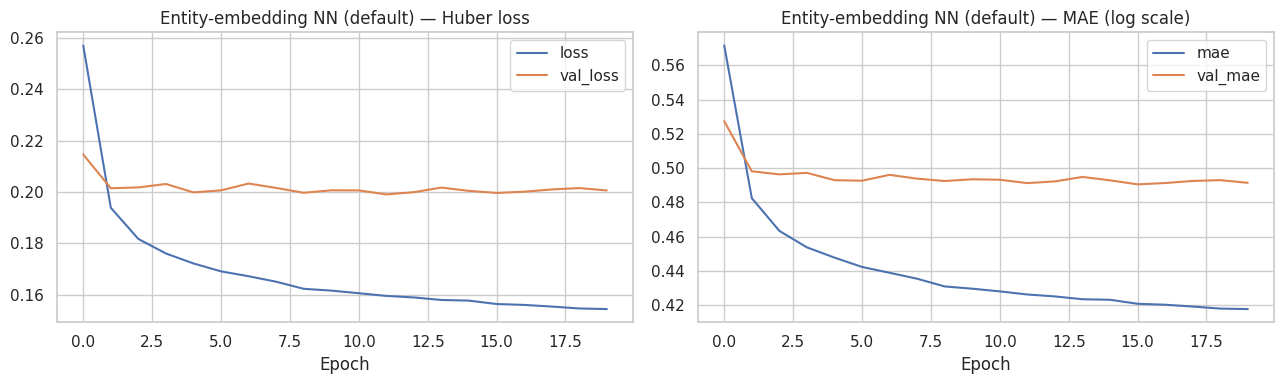

,Model,MAE,RMSE,R2
0,Neural Network B — Entity Embedding (default),34.368,52.318,0.448


In [31]:
def train_embedding_nn(model, epochs=60, batch_size=1024, verbose=2):
    return model.fit(
        X_train_emb, y_train_emb,
        validation_data=(X_val_emb, y_val_emb),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[
            EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)
        ],
        verbose=verbose
    )

embedding_history = train_embedding_nn(embedding_nn)
plot_history(embedding_history, "Entity-embedding NN (default)")

embedding_predictions = predict_embedding_nn(embedding_nn, X_val_emb)
display(record_result("Neural Network B — Entity Embedding (default)", embedding_predictions))

---
# 8. Model Optimization (Hyperparameter Tuning)
Hyperparameters are settings chosen *before* training, such as tree depth or learning rate. In each tuning step below, several configurations are trained on the training set and compared on the **validation set**. The 2015 test set is not used for any of these choices.

### 8.1 Ridge Regression — regularisation strength
`alpha` controls how strongly Ridge shrinks its coefficients. A larger alpha gives a simpler, more stable model; a smaller alpha fits the training data more closely. Four values (0.1, 1, 10 and 100) are compared, and the best by validation RMSE is kept as the final Ridge model.

**Results**
| α | MAE | RMSE | R² |
|---|---|---|---|
| **100** | **37.17** | **56.94** | **0.346** |
| 10 | 37.45 | 57.21 | 0.340 |
| 1 | 37.53 | 57.30 | 0.338 |
| 0.1 | 37.54 | 57.31 | 0.338 |

The strongest regularisation (α = 100) is best, but the whole range of α changes R² by only 0.008. Ridge's performance is limited by its **linear form**, not by its regularisation setting, which is why the non-linear models are needed.

In [32]:
ridge_tuning = []
ridge_models = {}

for alpha in [0.1, 1.0, 10.0, 100.0]:
    model = Ridge(alpha=alpha, solver="lsqr", max_iter=10000)
    model.fit(X_train_processed, y_train_log)
    preds = to_rspm_scale(model.predict(X_val_processed))
    ridge_models[alpha] = (model, preds)
    ridge_tuning.append(evaluate_model(f"Ridge (alpha={alpha})", y_val, preds))

ridge_tuning_df = pd.DataFrame(ridge_tuning).sort_values("RMSE").reset_index(drop=True)
display(ridge_tuning_df)

best_alpha = float(ridge_tuning_df.loc[0, "Model"].split("=")[1].rstrip(")"))
best_ridge_model, best_ridge_predictions = ridge_models[best_alpha]
display(record_result(f"Ridge Regression (tuned, alpha={best_alpha})", best_ridge_predictions))

,Model,MAE,RMSE,R2
0,Ridge (alpha=100.0),37.167,56.943,0.3461
1,Ridge (alpha=10.0),37.448,57.211,0.3400
2,Ridge (alpha=1.0),37.530,57.300,0.3379
3,Ridge (alpha=0.1),37.540,57.311,0.3376


,Model,MAE,RMSE,R2
0,"Ridge Regression (tuned, alpha=100.0)",37.167,56.943,0.3461


### 8.2 XGBoost — tree depth, regularisation and number of trees
Three XGBoost configurations are compared:

| Configuration | Trees | Max depth | min_child_weight | L2 penalty (`reg_lambda`) | Idea |
|---|---|---|---|---|---|
| Default | 300 | 8 | 1 | 1 | the starting point from Section 6.5 |
| Regularised | 400 | 5 | 5 | 5 | shallower, more heavily penalised trees — less overfitting |
| Deeper | 250 | 10 | 3 | 2 | deeper trees that capture more complex interactions |

The configuration with the lowest validation RMSE is selected automatically and becomes `best_xgb_model`, which is used for the SHAP analysis and the final test.

**Results**
| Configuration | MAE | RMSE | R² |
|---|---|---|---|
| **Deeper** (250 trees, depth 10) | **33.85** | **50.39** | **0.488** |
| Default (300 trees, depth 8) | 34.06 | 50.47 | 0.486 |
| Regularised (400 trees, depth 5) | 34.46 | 50.63 | 0.483 |

The **Deeper** configuration is selected. Allowing deeper trees helps slightly, because the model can represent more detailed interactions between location, season and gas levels. The more heavily regularised, shallower trees are slightly worse. The three settings differ by only 0.005 in R², which shows XGBoost is **robust to these hyperparameters** — the remaining error comes from information missing from the features, not from the model settings.

In [33]:
xgb_configs = {
    "XGBoost - Default":     {"n_estimators": 300, "max_depth": 8,  "min_child_weight": 1, "reg_lambda": 1},
    "XGBoost - Regularised": {"n_estimators": 400, "max_depth": 5,  "min_child_weight": 5, "reg_lambda": 5},
    "XGBoost - Deeper":      {"n_estimators": 250, "max_depth": 10, "min_child_weight": 3, "reg_lambda": 2},
}

xgb_tuning, xgb_models = [], {}

for name, params in xgb_configs.items():
    model = XGBRegressor(
        **params,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=-1,
        random_state=SEED
    )
    model.fit(X_train_processed, y_train)
    preds = model.predict(X_val_processed)
    xgb_models[name] = (model, preds)
    xgb_tuning.append(evaluate_model(name, y_val, preds))

xgb_tuning_df = pd.DataFrame(xgb_tuning).sort_values("RMSE").reset_index(drop=True)
display(xgb_tuning_df)

best_xgb_name = xgb_tuning_df.loc[0, "Model"]
best_xgb_model, best_xgb_predictions = xgb_models[best_xgb_name]
print("Selected configuration:", best_xgb_name, xgb_configs[best_xgb_name])

display(record_result("XGBoost (tuned)", best_xgb_predictions))

,Model,MAE,RMSE,R2
0,XGBoost - Deeper,33.849,50.388,0.4880
1,XGBoost - Default,34.060,50.465,0.4864
2,XGBoost - Regularised,34.460,50.627,0.4831


Selected configuration: XGBoost - Deeper {'n_estimators': 250, 'max_depth': 10, 'min_child_weight': 3, 'reg_lambda': 2}


,Model,MAE,RMSE,R2
0,XGBoost (tuned),33.849,50.388,0.488


### 8.3 Neural Network B — architecture and training hyperparameters
The entity-embedding network is tuned over four configurations. The default from Section 7.7 is reused rather than retrained; three alternatives are trained here.

| Configuration | Hidden layers | Dropout | Learning rate | Embedding sizes (state / location / type) | Idea |
|---|---|---|---|---|---|
| Default | 256-128-64 | 0.2 | 0.001 | 8 / 16 / 3 | baseline (Section 7.7) |
| Wider | 512-256-128 | 0.3 | 0.001 | 8 / 24 / 3 | more capacity, stronger dropout |
| Deeper | 256-256-128-64 | 0.2 | 0.0005 | 8 / 32 / 3 | extra layer, richer location embedding, slower learning |
| Compact | 128-64 | 0.1 | 0.002 | 4 / 12 / 2 | smaller network — tests whether a simpler model generalises better |

The configuration with the lowest validation RMSE becomes `best_nn_model`. A bar chart compares the four configurations, followed by the learning curve of the winner.

*Runtime note: about 2–4 minutes per configuration on CPU; less on a Kaggle GPU.*

**Results**
| Configuration | MAE | RMSE | R² | Epochs |
|---|---|---|---|---|
| **Deeper** (256-256-128-64, lr 0.0005, location embedding 32) | **33.88** | **52.00** | **0.455** | 22 |
| Compact (128-64, lr 0.002) | 34.06 | 52.36 | 0.447 | 13 |
| Wider (512-256-128, dropout 0.3) | 34.45 | 52.49 | 0.444 | 15 |
| Default (256-128-64) | 34.37 | 52.53 | 0.444 | 13 |

- The **Deeper** configuration wins. Tuning lowered the RMSE by 0.5 and raised R² from 0.444 to **0.455**, which overtakes the Random Forest (0.451).
- Its advantages are a **richer location embedding** (32 numbers instead of 16) and a **lower learning rate**, which let it train for 22 epochs instead of 13 and settle into a better solution.
- The **Wider** network (twice as many neurons, stronger dropout) is no better than the default, so the network's size is not the bottleneck.
- On MAE, the tuned network (33.88) is now **practically equal to the tuned XGBoost (33.85)**.
- The learning curve of the winning configuration shows the same healthy pattern as before: the validation loss falls and then levels off without rising, so there is no overfitting.


=== Training configuration: Wider ===
{'Model': 'Wider', 'MAE': 34.297, 'RMSE': np.float64(52.273), 'R2': 0.449, 'Epochs trained': 13}

=== Training configuration: Deeper ===
{'Model': 'Deeper', 'MAE': 33.937, 'RMSE': np.float64(51.972), 'R2': 0.4553, 'Epochs trained': 22}

=== Training configuration: Compact ===
{'Model': 'Compact', 'MAE': 33.964, 'RMSE': np.float64(52.725), 'R2': 0.4394, 'Epochs trained': 13}


,Model,MAE,RMSE,R2,Epochs trained
0,Deeper,33.937,51.972,0.4553,22
1,Wider,34.297,52.273,0.4490,13
2,Default,34.368,52.318,0.4480,20
3,Compact,33.964,52.725,0.4394,13


Selected configuration: Deeper


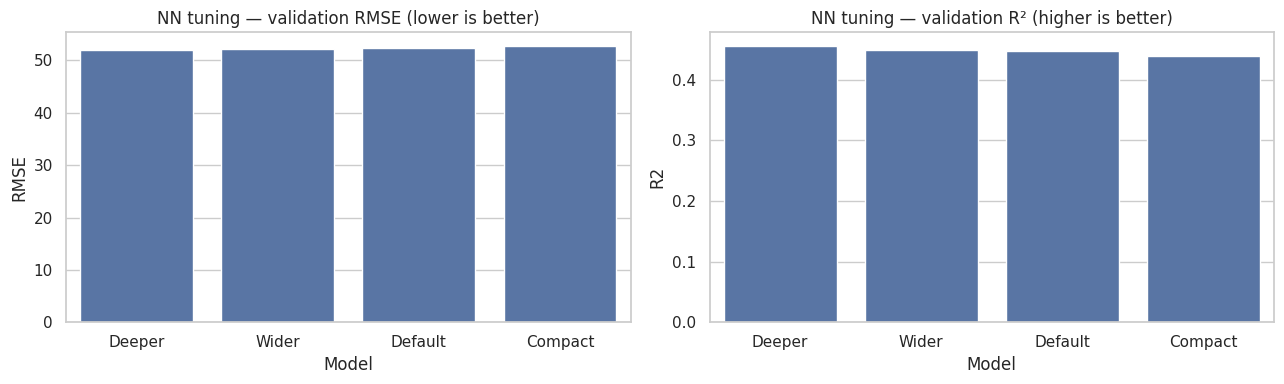

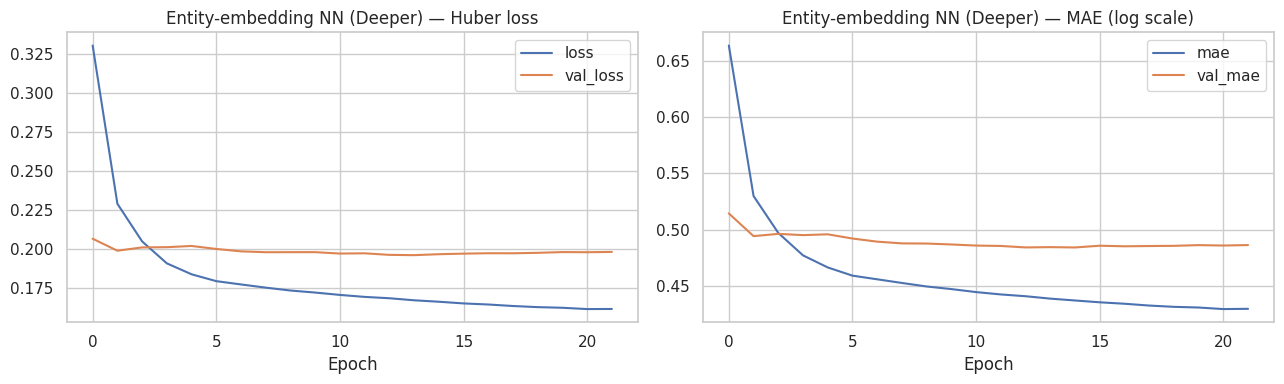

,Model,MAE,RMSE,R2
0,Neural Network B — Entity Embedding (tuned: De...,33.937,51.972,0.4553


In [34]:
nn_configs = {
    "Wider":   {"units": (512, 256, 128),     "dropout": 0.3, "learning_rate": 1e-3,
                "embedding_dims": {"state": 8, "location": 24, "type": 3}},
    "Deeper":  {"units": (256, 256, 128, 64), "dropout": 0.2, "learning_rate": 5e-4,
                "embedding_dims": {"state": 8, "location": 32, "type": 3}},
    "Compact": {"units": (128, 64),           "dropout": 0.1, "learning_rate": 2e-3,
                "embedding_dims": {"state": 4, "location": 12, "type": 2}},
}

nn_tuning = [evaluate_model("Default", y_val, embedding_predictions)]
nn_models = {"Default": (embedding_nn, embedding_predictions, embedding_history)}

for name, config in nn_configs.items():
    print(f"\n=== Training configuration: {name} ===")
    model = build_embedding_nn(**config, name=f"embedding_nn_{name.lower()}")
    history = train_embedding_nn(model, verbose=0)
    preds = predict_embedding_nn(model, X_val_emb)
    nn_models[name] = (model, preds, history)
    result = evaluate_model(name, y_val, preds)
    result["Epochs trained"] = len(history.history["loss"])
    nn_tuning.append(result)
    print(result)

nn_tuning[0]["Epochs trained"] = len(embedding_history.history["loss"])
nn_tuning_df = pd.DataFrame(nn_tuning).sort_values("RMSE").reset_index(drop=True)
display(nn_tuning_df)

best_nn_name = nn_tuning_df.loc[0, "Model"]
best_nn_model, best_nn_predictions, best_nn_history = nn_models[best_nn_name]
best_nn_config = DEFAULT_NN_CONFIG if best_nn_name == "Default" else nn_configs[best_nn_name]
print("Selected configuration:", best_nn_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=nn_tuning_df, x="Model", y="RMSE", ax=axes[0])
axes[0].set_title("NN tuning — validation RMSE (lower is better)")
sns.barplot(data=nn_tuning_df, x="Model", y="R2", ax=axes[1])
axes[1].set_title("NN tuning — validation R² (higher is better)")
plt.tight_layout()
plt.show()

plot_history(best_nn_history, f"Entity-embedding NN ({best_nn_name})")

display(record_result(f"Neural Network B — Entity Embedding (tuned: {best_nn_name})", best_nn_predictions))

---
# 9. Validation Comparison of All Models
All models are compared side by side on the 2013–2014 validation set, sorted by RMSE (best first), and shown as bar charts of MAE and R².

**Results (validation, 2013–2014)**
| Rank | Model | MAE | RMSE | R² |
|---|---|---|---|---|
| 1 | **XGBoost (tuned)** | **33.85** | **50.39** | **0.488** |
| 2 | XGBoost (default) | 34.06 | 50.47 | 0.486 |
| 3 | **Entity-embedding NN (tuned)** | 33.88 | 52.00 | 0.455 |
| 4 | Random Forest | 35.14 | 52.20 | 0.451 |
| 5 | Entity-embedding NN (default) | 34.37 | 52.53 | 0.444 |
| 6 | MLP (one-hot) | 37.07 | 56.71 | 0.351 |
| 7 | Ridge Regression (tuned) | 37.17 | 56.94 | 0.346 |
| 8 | Ridge Regression (α = 10) | 37.45 | 57.21 | 0.340 |
| 9 | Median baseline | 50.55 | 71.70 | −0.037 |

**Discussion**
- **Every model clearly beats the baseline.** The best models cut the average error from 50.5 to about 34 µg/m³, a 33% reduction.
- **The tuned XGBoost is the best model on validation** in all three metrics.
- **The tuned entity-embedding network matches XGBoost on MAE** (33.88 vs 33.85) but has a higher RMSE. It is trained on the log scale, which makes it more conservative on the rare very high readings — and RMSE punishes exactly those large errors.
- **Architecture matters more than size for neural networks.** Replacing one-hot inputs with learned embeddings raised R² from 0.351 to 0.455, while making the network wider gave nothing.
- **Non-linear models beat linear ones.** Ridge and the one-hot MLP both stall at R² ≈ 0.35; the tree ensembles and the embedding network reach 0.45–0.49.
- **A shared ceiling.** The four best models all lie between R² 0.44 and 0.49, despite very different designs. This points to a limit set by the **features**, not the algorithms. Gas levels, place and season explain about half of the day-to-day variation in RSPM; the rest depends on information the dataset does not contain, such as weather, wind and local events.

,Model,MAE,RMSE,R2
0,XGBoost (tuned),33.849,50.388,0.4880
1,XGBoost (default),34.060,50.465,0.4864
2,Neural Network B — Entity Embedding (tuned: De...,33.937,51.972,0.4553
3,Random Forest,35.142,52.198,0.4506
4,Neural Network B — Entity Embedding (default),34.368,52.318,0.4480
5,Neural Network A — MLP (one-hot),37.068,56.712,0.3514
6,"Ridge Regression (tuned, alpha=100.0)",37.167,56.943,0.3461
7,Ridge Regression (alpha=10),37.448,57.211,0.3400
8,Median Baseline,50.545,71.696,-0.0366


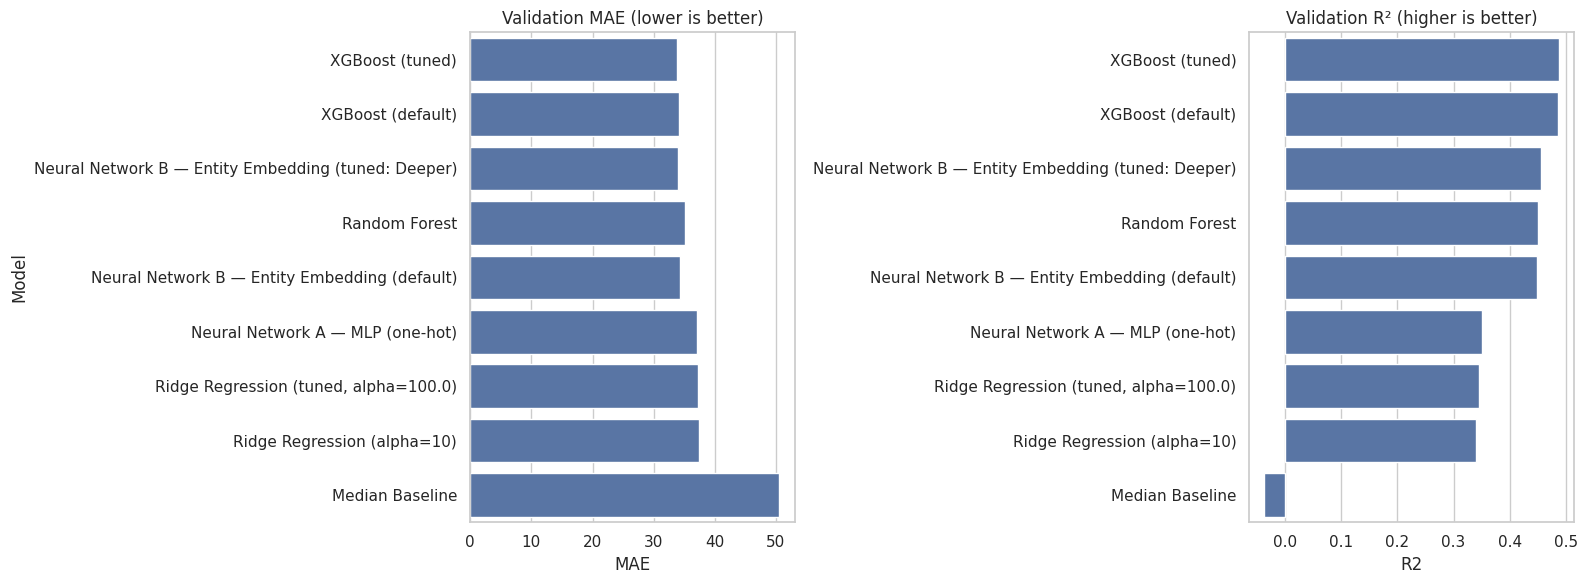

In [35]:
comparison_df = (
    pd.DataFrame(validation_results)
    .drop_duplicates(subset="Model", keep="last")
    .sort_values("RMSE")
    .reset_index(drop=True)
)
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=comparison_df, y="Model", x="MAE", ax=axes[0])
axes[0].set_title("Validation MAE (lower is better)")
sns.barplot(data=comparison_df, y="Model", x="R2", ax=axes[1])
axes[1].set_title("Validation R² (higher is better)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

---
# 10. Model Analysis and Discussion

## 10.1 Explainable AI with SHAP (tuned XGBoost)
**SHAP** (SHapley Additive exPlanations) explains a prediction by splitting it into contributions from each feature, measured against the model's average prediction. A positive SHAP value means the feature pushed that prediction **up** (more pollution); a negative value means it pushed it **down**. `TreeExplainer` computes exact SHAP values for tree models efficiently.

SHAP values are computed for a reproducible random sample of 1,000 validation records, which is enough to show the overall patterns while keeping the computation fast. The analysis uses the tuned XGBoost model.

In [36]:
rng = np.random.default_rng(SEED)
sample_size = min(1000, X_val_processed.shape[0])
sample_indices = rng.choice(X_val_processed.shape[0], size=sample_size, replace=False)

X_shap = X_val_processed[sample_indices]
X_shap_dense = X_shap.toarray() if issparse(X_shap) else np.asarray(X_shap)

explainer = shap.TreeExplainer(best_xgb_model)
shap_values = explainer.shap_values(X_shap)

print("Transformed features:", len(feature_names))
print("SHAP values shape   :", shap_values.shape)

Transformed features: 261
SHAP values shape   : (1000, 261)


### 10.1.1 SHAP summary (beeswarm) plot
Each dot is one validation record. Its **horizontal position** is that feature's SHAP value (its effect on the prediction), and its **colour** is the feature's value (red = high, blue = low). Features are ranked by overall importance from top to bottom.

**Insights**
- **NO₂ is the most influential feature.** High NO₂ (red) pushes predictions up by as much as +50 to +150 µg/m³, and low NO₂ (blue) pulls them down by up to about −50. This agrees with the EDA finding that NO₂ is the gas most correlated with RSPM, since both come from traffic and combustion.
- **State membership comes next.** Being in **Uttar Pradesh, Punjab, Rajasthan or Delhi** (red dots) raises the prediction by roughly +20 to +100, while **Kerala, Tamil Nadu, Karnataka, Maharashtra and West Bengal** lower it by about −10 to −35. This matches the north–south pattern found in EDA (Section 4.3).
- **Season matters:** `month_cos` and `month_sin` together shift predictions by about ±15 µg/m³, reflecting the winter peak and monsoon dip.
- **SO₂** has a smaller positive effect, consistent with its weaker correlation with RSPM.
- **Industrial areas** raise predictions. After the area-type labels were merged in Section 5.1, *Industrial* is a single feature instead of being split across "Industrial Area" and "Industrial Areas". Individual cities such as **Gwalior, Chandrapur, Jodhpur and Guwahati** also appear among the top 20 with strong positive effects.
- **Year** has a small effect: later years push predictions slightly down, matching the post-2011 decline.

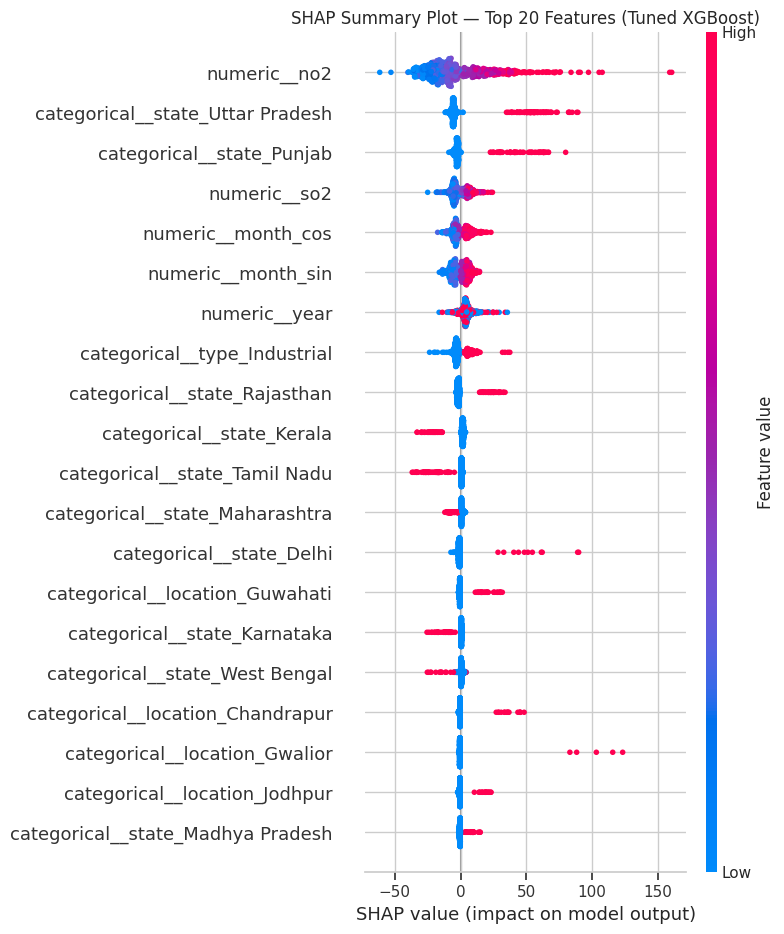

In [37]:
shap.summary_plot(shap_values, X_shap_dense, feature_names=feature_names, max_display=20, show=False)
plt.title("SHAP Summary Plot — Top 20 Features (Tuned XGBoost)")
plt.tight_layout()
plt.show()

### 10.1.2 Global feature importance (mean |SHAP|)
The bar chart and table rank features by their **average absolute SHAP value** — how many µg/m³ each feature moves the prediction, on average, in either direction.

**Insights**
- **NO₂ leads clearly with 19.2 µg/m³**, almost twice the next feature.
- **Uttar Pradesh (10.5)** and **Punjab (5.5)** follow, then **SO₂ (5.4)** and the two **month features (5.3 and 5.1)**.
- **Combined, the two month features (10.3) are as important as the largest state effect**, which confirms that seasonality is a major driver.
- **Year (5.0)** and **Industrial area type (4.7)** contribute moderately. The industrial effect is clearer than in the first version of the notebook (3.3), because its duplicate labels are now merged into one feature.
- The ranking agrees with domain knowledge — combustion gases, geography and season — which builds confidence that the model has learned real patterns rather than artefacts.

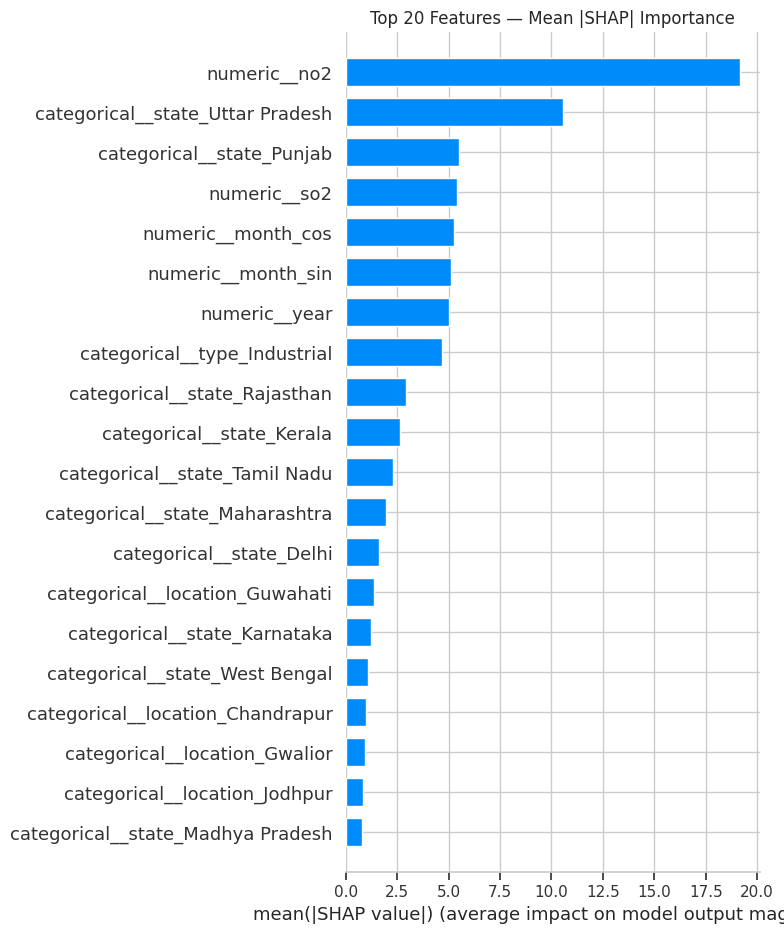

,Feature,Mean_Absolute_SHAP
0,numeric__no2,19.165394
1,categorical__state_Uttar Pradesh,10.548494
2,categorical__state_Punjab,5.488069
3,numeric__so2,5.421310
4,numeric__month_cos,5.254639
5,numeric__month_sin,5.094999
6,numeric__year,5.001173
7,categorical__type_Industrial,4.664745
8,categorical__state_Rajasthan,2.909575
9,categorical__state_Kerala,2.622756


In [38]:
shap.summary_plot(shap_values, X_shap_dense, feature_names=feature_names,
                  plot_type="bar", max_display=20, show=False)
plt.title("Top 20 Features — Mean |SHAP| Importance")
plt.tight_layout()
plt.show()

shap_importance = (
    pd.DataFrame({"Feature": feature_names, "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)})
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)
display(shap_importance.head(20))

### 10.1.3 SHAP dependence plot — NO₂
This plot shows how the SHAP value of NO₂ changes with the (standardised) NO₂ reading. The x-axis is in standard deviations from the training mean: 0 is an average NO₂ level and 2 is two standard deviations above it.

**Insights**
- The relationship is **close to linear and positive** across the normal range (about −1 to +3 standard deviations). As NO₂ rises, the model raises its RSPM prediction steadily, from about −50 to +75 µg/m³.
- Below-average NO₂ consistently lowers the prediction, which typically means cleaner, low-traffic locations.
- The handful of extreme NO₂ readings (more than 5 standard deviations) **level off at about +90 to +160** instead of growing without limit. Tree models cannot extrapolate beyond what they saw in training, which is exactly why XGBoost did not suffer the explosive predictions that Ridge and the MLP produced (Section 6.3).

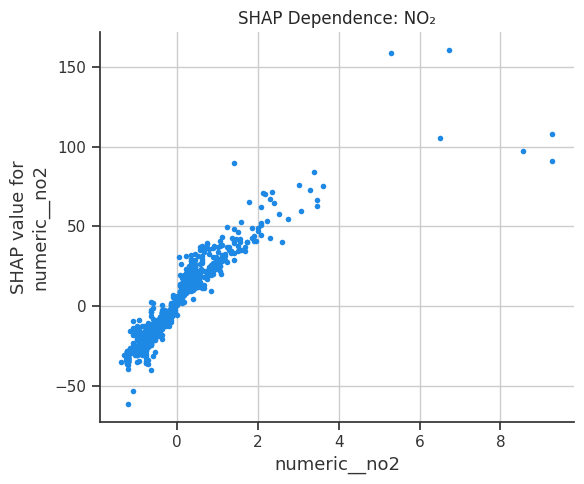

In [39]:
shap.dependence_plot("numeric__no2", shap_values, X_shap_dense,
                     feature_names=feature_names, interaction_index=None, show=False)
plt.title("SHAP Dependence: NO₂")
plt.tight_layout()
plt.show()

### 10.1.4 SHAP dependence plot — seasonal influence (`month_sin`)
`month_sin` is positive from January to May (highest around March) and negative from July to November (lowest around September). The plot shows the SHAP value for each of its values.

**Insights**
- When `month_sin` is **high (January–May)**, its SHAP values are **positive (about +5 to +15)**, raising the prediction in the dry, high-pollution months.
- When `month_sin` is **low (July–November)**, its SHAP values are **negative (about −5 to −16)**, lowering the prediction during and just after the monsoon.
- Together with `month_cos`, which separates winter (December–January) from summer, the model has learned the same seasonal cycle seen in EDA (Section 4.6), **without being told** which months are monsoon months.

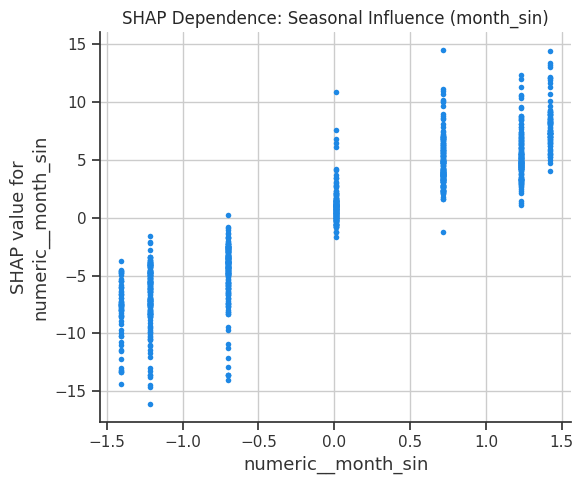

In [40]:
shap.dependence_plot("numeric__month_sin", shap_values, X_shap_dense,
                     feature_names=feature_names, interaction_index=None, show=False)
plt.title("SHAP Dependence: Seasonal Influence (month_sin)")
plt.tight_layout()
plt.show()

## 10.2 Error Analysis (tuned XGBoost, validation set)
The following plots examine **where and why** the model makes mistakes. A residual is *actual − predicted*: a positive residual means the model **under-predicted**, a negative one means it **over-predicted**.

### 10.2.1 Actual vs predicted RSPM
Each point is one validation record. Points on the dashed diagonal are perfect predictions.

**Insights**
- For typical concentrations (up to about 250 µg/m³) the points follow the diagonal, but with a wide spread — the model captures the general level but not the day-to-day variation.
- Predictions rarely exceed about **400 µg/m³**, even when the actual value is 600–1,000. The model **systematically under-predicts severe pollution days**.
- This is expected. The features (gases, place, season, year) describe *typical* conditions, while extreme days are driven by factors the dataset does not contain: weather (wind, rain, temperature inversions), dust storms, festivals (fireworks) and crop burning on a particular day.

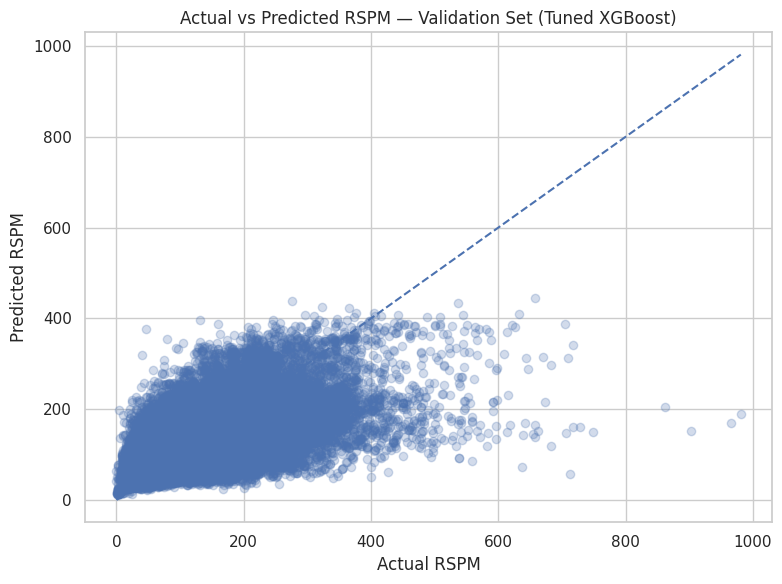

In [41]:
plt.figure(figsize=(8, 6))
plt.scatter(y_val, best_xgb_predictions, alpha=0.25)
lims = [0, max(y_val.max(), best_xgb_predictions.max())]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Actual RSPM")
plt.ylabel("Predicted RSPM")
plt.title("Actual vs Predicted RSPM — Validation Set (Tuned XGBoost)")
plt.tight_layout()
plt.show()

### 10.2.2 Distribution of prediction errors
A histogram of the residuals.

**Insights**
- The residuals are centred close to **zero**, so the model has no large overall bias.
- The distribution is **right-skewed**: the long tail on the positive side represents high-pollution days the model under-predicted, while large negative errors (over-prediction) are less common and smaller.

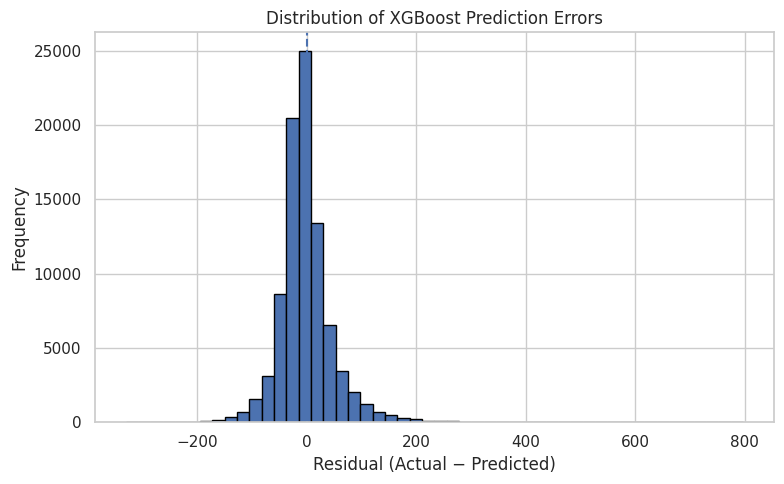

In [42]:
residuals = np.asarray(y_val) - np.asarray(best_xgb_predictions)

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50, edgecolor="black")
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (Actual − Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of XGBoost Prediction Errors")
plt.tight_layout()
plt.show()

### 10.2.3 Residuals vs predicted values
**Insights**
- The spread of residuals **widens as the predicted value increases** (heteroscedasticity): the model is more precise for clean-air predictions than for polluted ones.
- The lower edge forms a diagonal line because RSPM cannot be negative, so the largest possible over-prediction equals the prediction itself.
- Residuals of up to **+800** occur at moderate predictions (100–200), which are the unexpected severe-pollution events.

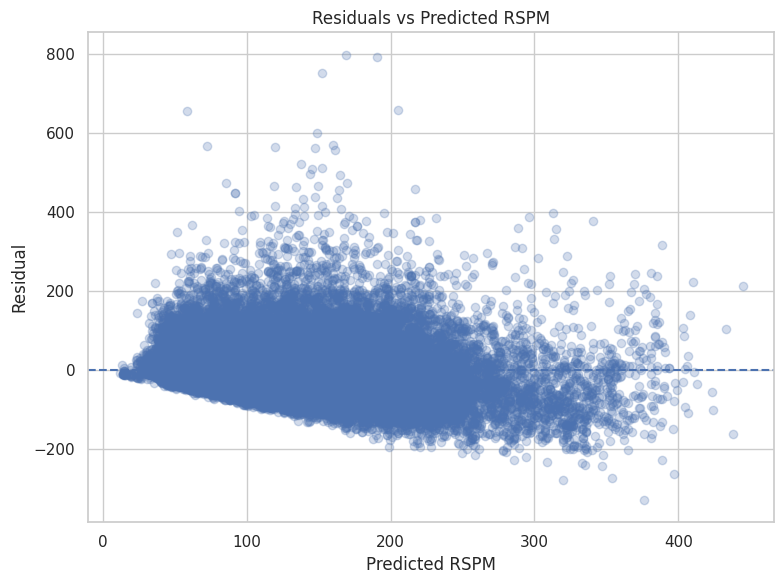

In [43]:
plt.figure(figsize=(8, 6))
plt.scatter(best_xgb_predictions, residuals, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted RSPM")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted RSPM")
plt.tight_layout()
plt.show()

### 10.2.4 Error by pollution level
Validation records are grouped by their **actual** RSPM level, and the MAE and mean residual are calculated for each group.

**Insights**
| Actual RSPM | Records | MAE | Mean residual | Meaning |
|---|---|---|---|---|
| Below 50 | 18,404 | 30.3 | −30.0 | clean days are **over-predicted** |
| 50–100 | 33,690 | 22.3 | −13.8 | best accuracy — the most common range |
| 100–150 | 18,417 | 30.8 | +5.6 | nearly unbiased |
| 150–200 | 9,963 | 41.7 | +20.2 | starting to under-predict |
| Above 200 | 8,334 | 85.9 | **+73.6** | polluted days strongly **under-predicted** |

This is a classic **regression-to-the-mean** pattern: the model pulls predictions towards the typical level of 80–120 µg/m³. Its accuracy is best for the most common conditions and weakest at the extremes. From a public-health point of view the above-200 group matters most, so this is the model's main limitation and the main target for future work (adding weather data, previous-day readings and a loss function that weights high values more).

,RSPM_Category,Sample_Count,MAE,Mean_Residual
0,Below 50,18404,30.298325,-29.981599
1,50-100,33690,22.273658,-13.752775
2,100-150,18417,30.789993,5.610400
3,150-200,9963,41.699325,20.167201
4,Above 200,8334,85.863344,73.587796


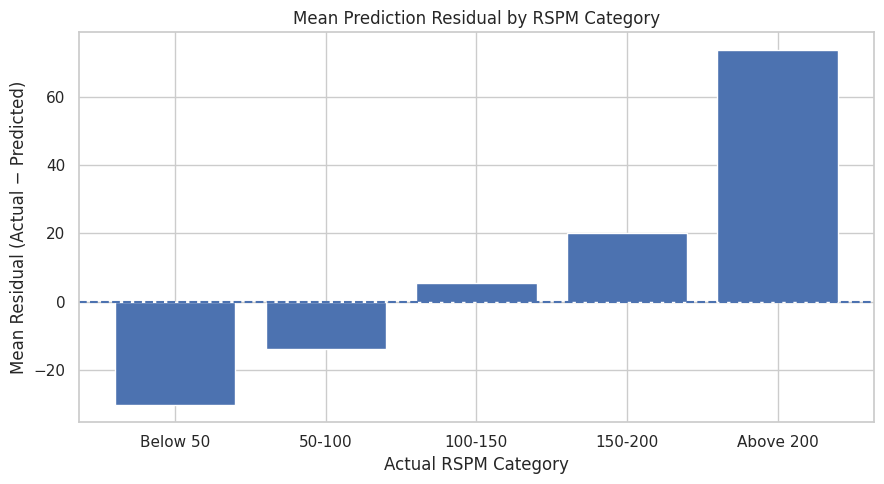

In [44]:
error_analysis = pd.DataFrame({
    "Actual_RSPM": np.asarray(y_val),
    "Predicted_RSPM": np.asarray(best_xgb_predictions)
})
error_analysis["Residual"] = error_analysis["Actual_RSPM"] - error_analysis["Predicted_RSPM"]
error_analysis["Absolute_Error"] = error_analysis["Residual"].abs()

error_analysis["RSPM_Category"] = pd.cut(
    error_analysis["Actual_RSPM"],
    bins=[-np.inf, 50, 100, 150, 200, np.inf],
    labels=["Below 50", "50-100", "100-150", "150-200", "Above 200"]
)

error_by_range = error_analysis.groupby("RSPM_Category", observed=False).agg(
    Sample_Count=("Actual_RSPM", "count"),
    MAE=("Absolute_Error", "mean"),
    Mean_Residual=("Residual", "mean")
).reset_index()

display(error_by_range)

plt.figure(figsize=(9, 5))
plt.bar(error_by_range["RSPM_Category"].astype(str), error_by_range["Mean_Residual"])
plt.axhline(0, linestyle="--")
plt.xlabel("Actual RSPM Category")
plt.ylabel("Mean Residual (Actual − Predicted)")
plt.title("Mean Prediction Residual by RSPM Category")
plt.tight_layout()
plt.show()

### 10.2.5 Error by state
The MAE is calculated for every state with at least 100 validation records, and the 15 states with the largest errors are shown.

**Insights**
- **Delhi (MAE 77.2)** and **Rajasthan (66.9)** have the largest errors. Both have very high and highly variable pollution — Delhi from traffic and winter smog, Rajasthan from desert dust storms — which the features cannot anticipate.
- Haryana (51.3), Madhya Pradesh (47.4), West Bengal (47.2) and Jharkhand (46.5) follow.
- States with many records and moderate pollution are predicted much more accurately, for example **Maharashtra (13,059 records, MAE 34.5)** and **Tamil Nadu (MAE 29.8)**.
- The mean residual changes sign between states (for example Jharkhand −21.8, over-predicted; Nagaland +26.6, under-predicted). This shows that some local factors are not captured by a simple per-state effect.

,state,Sample_Count,MAE,Mean_Residual
5,Delhi,987,77.159508,-6.371585
22,Rajasthan,3837,66.914471,8.274463
8,Haryana,339,51.321088,22.085846
14,Madhya Pradesh,2787,47.433206,-7.783186
27,West Bengal,2260,47.165307,11.467337
11,Jharkhand,754,46.470678,-21.803102
2,Assam,5445,44.004064,16.800709
26,Uttarakhand,648,41.711396,-16.532948
25,Uttar Pradesh,8045,40.326546,-0.740367
18,Nagaland,398,38.700205,26.572337


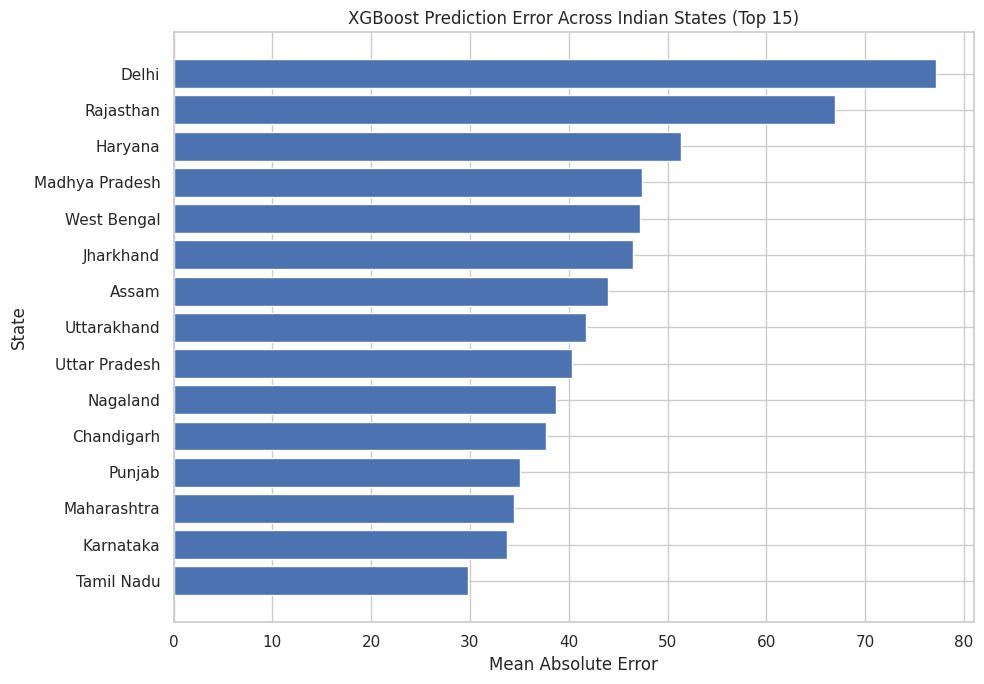

In [45]:
location_errors = val_df.copy()
location_errors["Actual_RSPM"] = np.asarray(y_val)
location_errors["Predicted_RSPM"] = np.asarray(best_xgb_predictions)
location_errors["Residual"] = location_errors["Actual_RSPM"] - location_errors["Predicted_RSPM"]
location_errors["Absolute_Error"] = location_errors["Residual"].abs()

state_error_analysis = (
    location_errors.groupby("state")
    .agg(
        Sample_Count=("Actual_RSPM", "count"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
    .query("Sample_Count >= 100")
    .sort_values("MAE", ascending=False)
)

display(state_error_analysis.head(15))

top_states = state_error_analysis.head(15).sort_values("MAE")
plt.figure(figsize=(10, 7))
plt.barh(top_states["state"].astype(str), top_states["MAE"])
plt.xlabel("Mean Absolute Error")
plt.ylabel("State")
plt.title("XGBoost Prediction Error Across Indian States (Top 15)")
plt.tight_layout()
plt.show()

---
# 11. Final Evaluation on the Untouched 2015 Test Set
All model choices — features, hyperparameters and model selection — were made using only the training and validation sets. The final models are now evaluated **once** on the 2015 test set, which was never used during development. This gives an honest estimate of how each model would perform on a future year.

The preprocessing steps (one-hot pipeline, embedding IDs, scaling statistics, prediction cap) are the ones fitted on the training data; **nothing is refitted on the test data**.

**Results (test, 2015 — 49,990 records)**
| Rank | Model | MAE | RMSE | R² | Validation R² |
|---|---|---|---|---|---|
| 1 | **XGBoost (tuned)** | **32.49** | **47.18** | **0.449** | 0.488 |
| 2 | **Entity-embedding NN (tuned)** | 32.52 | 47.24 | 0.447 | 0.455 |
| 3 | Random Forest | 33.56 | 49.09 | 0.403 | 0.451 |
| 4 | MLP (one-hot) | 37.50 | 53.74 | 0.285 | 0.351 |
| 5 | Ridge Regression (tuned) | 36.30 | 54.00 | 0.278 | 0.346 |
| 6 | Median baseline | 46.17 | 64.17 | −0.020 | −0.037 |

**Discussion**
- **XGBoost and the entity-embedding network finish in a virtual tie.** Their MAE differs by only 0.03 µg/m³ and their R² by 0.002. Both predict 2015 with an average error of about **32.5 µg/m³** and explain about **45%** of the variation. The deep-learning model, which uses no hand-built one-hot features, reaches the same level as the best traditional model.
- **The neural network generalises best.** Its R² falls by only 0.008 from validation to test, against 0.039 for XGBoost, 0.048 for the Random Forest and about 0.07 for Ridge and the MLP. Learned embeddings appear to transfer to a new year better than tree splits on one-hot columns.
- **The ranking is stable**: the same four groups (tree ensembles and the embedding network, then Ridge and the MLP, then the baseline) appear on both validation and test, so the model selection was not an accident of the validation years.
- **MAE is lower on test than on validation** (32.5 vs 33.9). 2015 was a cleaner and less variable year (standard deviation 63.5 vs 70.4), which makes absolute errors smaller even though R² is slightly lower.
- Because the test set was never used for any decision, these figures are an **honest estimate of performance on a future year**.

FINAL TEST RESULTS (2015) — 49990 records


,Model,MAE,RMSE,R2
0,XGBoost (tuned),32.494,47.177,0.4488
1,Neural Network B — Entity Embedding (tuned: De...,33.005,47.549,0.4401
2,Random Forest,33.555,49.089,0.4033
3,Neural Network A — MLP (one-hot),37.499,53.735,0.2850
4,"Ridge Regression (tuned, alpha=100.0)",36.302,54.000,0.2779
5,Median Baseline,46.173,64.171,-0.0197


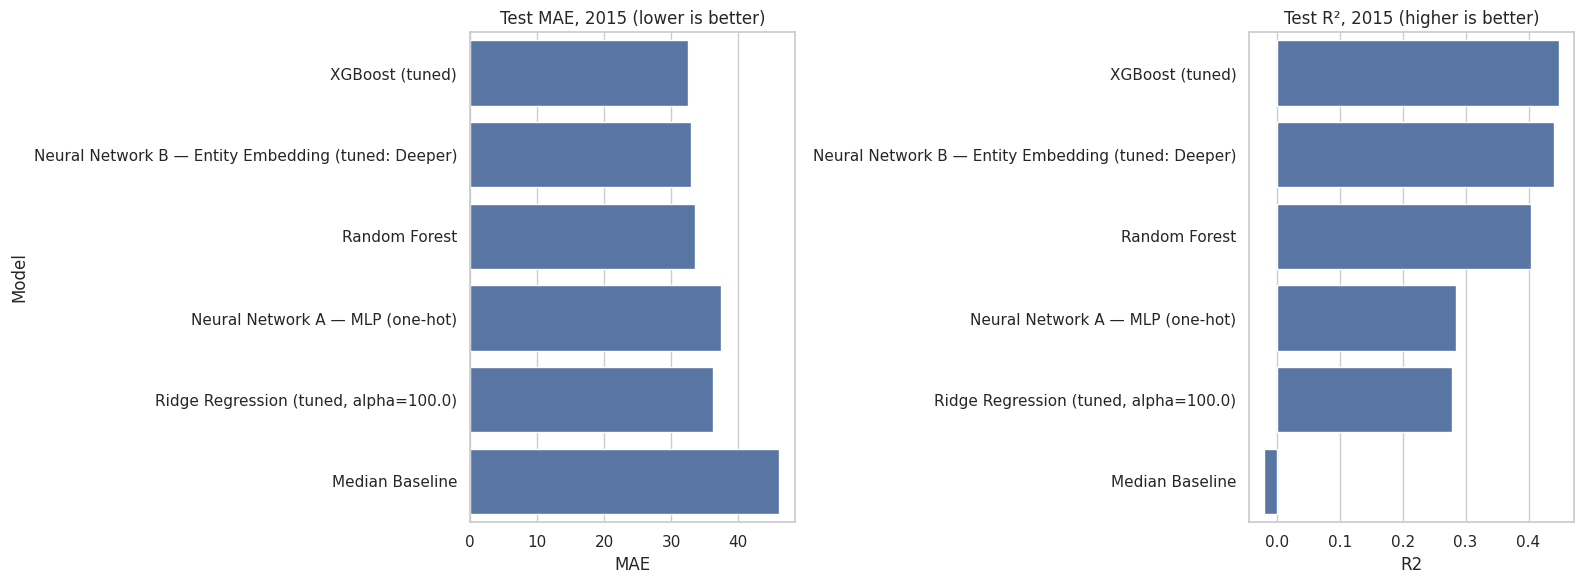

In [46]:
test_predictions = {
    "Median Baseline": dummy_model.predict(X_test_processed),
    f"Ridge Regression (tuned, alpha={best_alpha})": to_rspm_scale(best_ridge_model.predict(X_test_processed)),
    "Random Forest": rf_model.predict(X_test_processed),
    "XGBoost (tuned)": best_xgb_model.predict(X_test_processed),
    "Neural Network A — MLP (one-hot)": to_rspm_scale(
        mlp_model.predict(X_test_nn, batch_size=4096, verbose=0).ravel()),
    f"Neural Network B — Entity Embedding (tuned: {best_nn_name})": predict_embedding_nn(best_nn_model, X_test_emb),
}

test_results_df = (
    pd.DataFrame([evaluate_model(name, y_test, preds) for name, preds in test_predictions.items()])
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("FINAL TEST RESULTS (2015) —", len(y_test), "records")
display(test_results_df)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=test_results_df, y="Model", x="MAE", ax=axes[0])
axes[0].set_title("Test MAE, 2015 (lower is better)")
sns.barplot(data=test_results_df, y="Model", x="R2", ax=axes[1])
axes[1].set_title("Test R², 2015 (higher is better)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

### 11.1 Actual vs predicted on the test set — best traditional model vs best neural network
A side-by-side view of how the tuned XGBoost and the tuned entity-embedding network behave on 2015 data.

**Insights**
- Both models follow the diagonal for typical concentrations, and both **under-predict severe-pollution days**: actual readings of 400–900 µg/m³ receive predictions of about 100–300.
- **XGBoost spreads its predictions wider**, up to about 450 µg/m³. The **neural network is more conservative**, rarely going above about 330. This is the effect of training the network on the log scale, which pulls predictions towards the typical level.
- The two models therefore make **different kinds of errors with the same average size**. Combining them (for example, averaging their predictions) is a natural next step and could improve on either model alone.

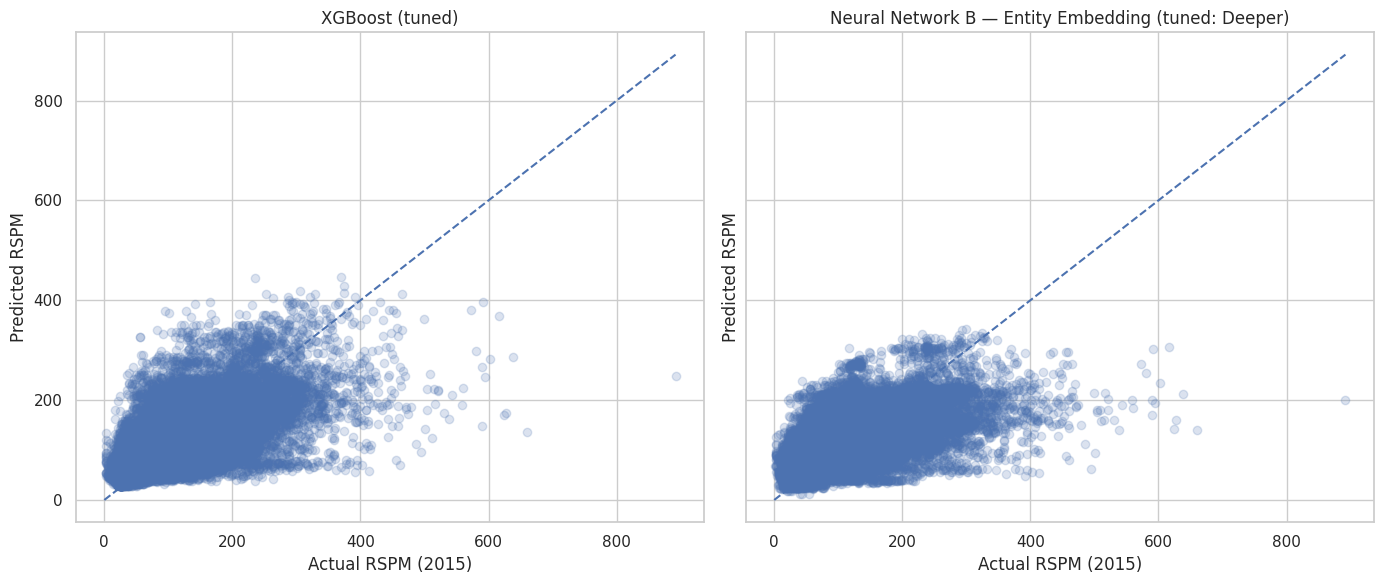

In [47]:
best_test_models = ["XGBoost (tuned)",
                    f"Neural Network B — Entity Embedding (tuned: {best_nn_name})"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
lims = [0, y_test.max()]

for ax, name in zip(axes, best_test_models):
    ax.scatter(y_test, test_predictions[name], alpha=0.2)
    ax.plot(lims, lims, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual RSPM (2015)")
    ax.set_ylabel("Predicted RSPM")

plt.tight_layout()
plt.show()

---
# 12. Export the Models and Data for the Dashboard
Everything the interactive dashboard needs is written to `/kaggle/working/dashboard_assets/` and packed into **`dashboard_assets.zip`**:

| File | Content |
|---|---|
| `models/preprocessor.joblib` | the fitted one-hot preprocessing pipeline (Section 5.3) |
| `models/xgboost_rspm.json` | the tuned XGBoost model |
| `models/nn_weights.npz` | the weights of the tuned entity-embedding network as plain NumPy arrays |
| `models/embedding_nn_rspm.keras` | the same network in Keras format (for reference) |
| `models/nn_metadata.json` | category IDs, medians, caps, scaling statistics and the log-prediction cap |
| `data/dashboard_data.csv.gz` | every cleaned record, with XGBoost and neural-network predictions for 2013–2015 |
| `data/*.csv` | model comparison, tuning, SHAP importance and error tables |
| `requirements.txt` | Python packages for the dashboard, pinned to the versions used here |

**Why export the network as NumPy weights?** The dashboard then needs no TensorFlow, which makes it much lighter and faster to deploy. The cell rebuilds the network's forward pass in plain NumPy and **checks that it gives the same predictions as the Keras model**, so the dashboard's neural-network predictions are guaranteed to match the notebook's.

After the run, download `dashboard_assets.zip` from the **Output** panel on the right-hand side of Kaggle.


In [48]:
import shutil, platform, sklearn, xgboost

ASSETS = "/kaggle/working/dashboard_assets"
MODEL_DIR, DATA_DIR = f"{ASSETS}/models", f"{ASSETS}/data"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# ---- 1. Preprocessing pipeline and models ----------------------------------
joblib.dump(preprocessor, f"{MODEL_DIR}/preprocessor.joblib")
best_xgb_model.save_model(f"{MODEL_DIR}/xgboost_rspm.json")
best_nn_model.save(f"{MODEL_DIR}/embedding_nn_rspm.keras")

# ---- 2. Neural-network weights as NumPy arrays ------------------------------
dense_layers = [l for l in best_nn_model.layers if isinstance(l, layers.Dense)]
bn_layers = [l for l in best_nn_model.layers if isinstance(l, layers.BatchNormalization)]

nn_weights = {}
for col in cat_cols:
    nn_weights[f"emb_{col}"] = best_nn_model.get_layer(f"{col}_embedding").get_weights()[0]
for i, layer in enumerate(dense_layers):
    nn_weights[f"dense_{i}_W"], nn_weights[f"dense_{i}_b"] = layer.get_weights()
bn_epsilons = []
for i, layer in enumerate(bn_layers):
    gamma, beta, mean, var = layer.get_weights()
    nn_weights[f"bn_{i}_gamma"], nn_weights[f"bn_{i}_beta"] = gamma, beta
    nn_weights[f"bn_{i}_mean"], nn_weights[f"bn_{i}_var"] = mean, var
    bn_epsilons.append(float(layer.epsilon))
np.savez_compressed(f"{MODEL_DIR}/nn_weights.npz", **nn_weights)

def numpy_forward(inputs):
    # Forward pass of the embedding network in plain NumPy (inference mode)
    numeric, *categorical = inputs
    parts = [numeric] + [nn_weights[f"emb_{c}"][ids.ravel()] for c, ids in zip(cat_cols, categorical)]
    x = np.concatenate(parts, axis=1)
    for i in range(len(bn_layers)):
        x = x @ nn_weights[f"dense_{i}_W"] + nn_weights[f"dense_{i}_b"]
        x = (nn_weights[f"bn_{i}_gamma"] * (x - nn_weights[f"bn_{i}_mean"])
             / np.sqrt(nn_weights[f"bn_{i}_var"] + bn_epsilons[i]) + nn_weights[f"bn_{i}_beta"])
        x = np.maximum(x, 0)
    last = len(dense_layers) - 1
    return (x @ nn_weights[f"dense_{last}_W"] + nn_weights[f"dense_{last}_b"]).ravel()

check = [part[:5000] for part in X_val_emb]
max_diff = np.abs(numpy_forward(check) - best_nn_model.predict(check, verbose=0).ravel()).max()
print(f"NumPy vs Keras forward pass — maximum difference: {max_diff:.2e}")
assert max_diff < 1e-3, "NumPy forward pass does not match the Keras model"

nn_metadata = {
    "features": features,
    "cat_cols": cat_cols,
    "cat_maps": cat_maps,
    "numeric_columns": list(num_mean.index),
    "nn_medians": nn_medians,
    "nn_caps": nn_caps,
    "num_mean": num_mean.astype(float).to_dict(),
    "num_std": num_std.astype(float).to_dict(),
    "y_log_mean": y_log_mean,
    "y_log_std": y_log_std,
    "log_cap": float(LOG_CAP),
    "n_hidden_layers": len(bn_layers),
    "bn_epsilons": bn_epsilons,
    "best_xgb_config": best_xgb_name,
    "best_nn_config": best_nn_name,
    "train_years": [int(train_df["year"].min()), int(train_df["year"].max())],
}
with open(f"{MODEL_DIR}/nn_metadata.json", "w") as f:
    json.dump(nn_metadata, f, indent=2)

# ---- 3. Data for the dashboard ----------------------------------------------
dash = pd.concat([
    train_df.assign(split="Train"),
    val_df.assign(split="Validation"),
    test_df.assign(split="Test"),
])
dash["pred_xgb"] = np.nan
dash["pred_nn"] = np.nan
holdout = dash["split"] != "Train"
dash.loc[holdout, "pred_xgb"] = best_xgb_model.predict(preprocessor.transform(dash.loc[holdout, features]))
dash.loc[holdout, "pred_nn"] = predict_embedding_nn(best_nn_model, make_embedding_inputs(dash.loc[holdout]))

dash = dash[["date", "year", "month", "state", "location", "type", "so2", "no2", "rspm",
             "split", "pred_xgb", "pred_nn"]].copy()
dash["date"] = dash["date"].dt.strftime("%Y-%m-%d")
dash[["so2", "no2", "rspm", "pred_xgb", "pred_nn"]] = dash[["so2", "no2", "rspm", "pred_xgb", "pred_nn"]].round(1)
dash.to_csv(f"{DATA_DIR}/dashboard_data.csv.gz", index=False, compression="gzip")

comparison_df.to_csv(f"{DATA_DIR}/validation_results.csv", index=False)
test_results_df.to_csv(f"{DATA_DIR}/test_results.csv", index=False)
ridge_tuning_df.to_csv(f"{DATA_DIR}/tuning_ridge.csv", index=False)
xgb_tuning_df.to_csv(f"{DATA_DIR}/tuning_xgboost.csv", index=False)
nn_tuning_df.to_csv(f"{DATA_DIR}/tuning_neural_network.csv", index=False)
shap_importance.head(30).to_csv(f"{DATA_DIR}/shap_importance.csv", index=False)

# ---- 4. Requirements for the dashboard (pinned to this environment) ---------
requirements = [
    "streamlit>=1.40",
    "plotly>=5.24",
    "pandas",
    "numpy",
    f"scikit-learn=={sklearn.__version__}",
    f"xgboost=={xgboost.__version__}",
    "joblib",
]
with open(f"{ASSETS}/requirements.txt", "w") as f:
    f.write("\n".join(requirements) + "\n")

# ---- 5. Zip everything --------------------------------------------------------
shutil.make_archive("/kaggle/working/dashboard_assets", "zip", ASSETS)

print("\nPython version used here:", platform.python_version(), "(choose the same on Streamlit Cloud)")
print("\nFiles exported:")
for root, _, files in os.walk(ASSETS):
    for file in sorted(files):
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / 1024**2
        flag = "  <-- larger than GitHub's 25 MB browser-upload limit" if size_mb > 25 else ""
        print(f"{os.path.relpath(path, ASSETS):40s} {size_mb:8.2f} MB{flag}")
print(f"\ndashboard_assets.zip: {os.path.getsize('/kaggle/working/dashboard_assets.zip') / 1024**2:.1f} MB")


NumPy vs Keras forward pass — maximum difference: 2.38e-07

Python version used here: 3.13.16 (choose the same on Streamlit Cloud)

Files exported:
requirements.txt                             0.00 MB
data/dashboard_data.csv.gz                   3.50 MB
data/shap_importance.csv                     0.00 MB
data/test_results.csv                        0.00 MB
data/tuning_neural_network.csv               0.00 MB
data/tuning_ridge.csv                        0.00 MB
data/tuning_xgboost.csv                      0.00 MB
data/validation_results.csv                  0.00 MB
models/embedding_nn_rspm.keras               1.59 MB
models/nn_metadata.json                      0.01 MB
models/nn_weights.npz                        0.46 MB
models/preprocessor.joblib                   0.01 MB
models/xgboost_rspm.json                     9.68 MB

dashboard_assets.zip: 8.3 MB


---
# 13. Conclusion
This project built and compared six models for predicting daily RSPM (PM10) concentrations at Indian monitoring stations, using a strict chronological split so that every model was judged on years it had never seen.

**Main findings**
1. **Best models.** The tuned **XGBoost** and the tuned **entity-embedding neural network** performed best and were practically tied on the untouched 2015 test set: MAE ≈ **32.5 µg/m³** and R² ≈ **0.45**. That is a 30% lower error than the median baseline (MAE 46.2).
2. **Deep learning.** How the inputs are represented decided the neural networks' success. A standard MLP on one-hot inputs overfitted after a single epoch (test R² 0.285). Replacing the one-hot columns with learned embeddings for state, location and area type lifted test R² to 0.447. That network also generalised best from validation to test.
3. **Explainability.** SHAP shows the models learned physically meaningful patterns. **NO₂** (a marker of traffic and combustion) is the strongest driver. It is followed by **location**, with the Indo-Gangetic states (Uttar Pradesh, Punjab, Rajasthan, Delhi) raising predictions and the southern states lowering them, then **season** (winter highs, monsoon lows) and **industrial area type**.
4. **Data cleaning mattered.** Prediction capping fixed the exploding Ridge and MLP predictions (from R² ≈ −239,000 to 0.34). Merging the duplicate category labels (area type, Uttaranchal/Uttarakhand, Calcutta/Kolkata) made the explanations cleaner.

**Limitations**
- All models **under-predict severe-pollution days**: above 200 µg/m³ the tuned XGBoost under-predicts by 74 µg/m³ on average. These are the most important days for public health.
- The best models share a ceiling of about R² 0.45–0.49. The available features — two gases, place, season and year — explain only about half of the variation; **weather** (wind, rain, temperature inversions) and **local events** (crop burning, festivals, dust storms) are missing from the dataset.
- Stations and states that first appear after 2012 (6.4% of validation records) have no history of their own. The embedding network represents them with a single learned "average station" embedding (Section 7.5), which is better than a random one but cannot capture their individual character.

**Future work**
- Add **meteorological data** and **previous-day RSPM readings** (lag features), which are the strongest known predictors of daily particulate levels.
- Use a loss function that weights high-pollution days more heavily, to reduce under-prediction where it matters most.
- Combine XGBoost and the embedding network into an **ensemble**, since they make different kinds of errors.
- The exported models (Section 12) are deployed in an interactive **dashboard** for exploring the data and making live predictions by state, city and season.